In [1]:
import os
os.environ["WANDB_MODE"] = "disabled"  # OKB calls wandb.log/define_metric internally; no-ops these

import sys
OKB_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
SF_FSA_VI_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", "..", "RM", "sf-fsa-vi"))
for root in (OKB_ROOT, SF_FSA_VI_ROOT):
    if root not in sys.path:
        sys.path.insert(0, root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import wandb
wandb.init(mode="disabled")

# `Office-v0` is registered under old `gym` (RM/sf-fsa-vi/envs/__init__.py), while OKB is
# built on `gymnasium` -- both packages are installed side by side in the `okb` env
# specifically so this notebook can bridge them (see Section 1 below).
import gym as old_gym
import gymnasium as gym
from gymnasium import spaces
import envs  # noqa: F401 -- registers Office-v0 (and Delivery-v0, DoubleSlit-v0, ...) in old gym

from rl.successor_features.okb import OKB
from rl.successor_features.ols import OLS
from rl.utils.utils import seed_everything
from rl.utils.eval import policy_evaluation_mo

%matplotlib inline

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


/opt/anaconda3/envs/okb/lib/python3.10/site-packages/flax/configurations.py:42: DeprecationWarning: jax.config.define_bool_state is deprecated. Please use other libraries for configuration instead.
  return jax_config.define_bool_state('flax_' + name, default, help)


In [2]:
SEED = 0
GAMMA = 0.99
ADD_OBJ_TO_START = True   # mirrors office_ccs_results.ipynb: register every object cell as a valid start state too
PHI_OBJ_TYPES = ["C1", "C2", "O1", "O2", "M1", "M2"]

seed_everything(SEED)

In [3]:
class OfficeGymnasiumEnv(gym.Env):
    """Wraps sf-fsa-vi's old-gym `Office-v0` so it satisfies OKB's gymnasium contract:
    5-tuple step/reset, gymnasium space classes, `reward_dim`/`reward_space`, and the
    per-feature vector `info['phi']` returned as the actual reward.
    """

    def __init__(self, add_obj_to_start=True, random_act_prob=0.0):
        self._env = old_gym.make("Office-v0", add_obj_to_start=add_obj_to_start, random_act_prob=random_act_prob)
        self.core = self._env.unwrapped  # the raw Office instance -- MAP, initial states, feat_dim, ...
        self.height, self.width = self.core.height, self.core.width

        self.action_space = spaces.Discrete(self.core.action_space.n)
        self.observation_space = spaces.Box(low=0.0, high=1.0, shape=(2,), dtype=np.float32)

        self.reward_dim = self.core.feat_dim
        self.reward_space = spaces.Box(low=0.0, high=1.0, shape=(self.reward_dim,), dtype=np.float32)

    def _normalize(self, obs):
        # raw obs is (row, col) as integers; Box declares [0, 1], so normalize to match
        return np.array([obs[0] / (self.height - 1), obs[1] / (self.width - 1)], dtype=np.float32)

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            self._env.seed(seed)
        state = None if options is None else options.get("state")
        obs = self._env.reset(state=state)
        return self._normalize(obs), {}

    def step(self, action):
        obs, _scalar_reward, done, info = self._env.step(int(action))
        # old gym's TimeLimit wrapper (applied via gym.envs.register(max_episode_steps=200))
        # flags truncation this way instead of a separate return value
        truncated = info.pop("TimeLimit.truncated", False)
        terminated = bool(done) and not truncated
        reward = info["phi"].astype(np.float32)
        # `rl.utils.eval.eval_mo`/`policy_evaluation_mo` (used by SFOLS's GPI-based next_w,
        # Section 5 below) read the vector reward from `info["vector_reward"]`, not from the
        # return value -- populate it here too so those functions work directly with this env.
        info["vector_reward"] = reward
        return self._normalize(obs), reward, terminated, truncated, info


office_env = OfficeGymnasiumEnv(add_obj_to_start=ADD_OBJ_TO_START)
office_eval_env = OfficeGymnasiumEnv(add_obj_to_start=ADD_OBJ_TO_START)
print(f"action_space: {office_env.action_space}   observation_space: {office_env.observation_space}")
print(f"reward_dim: {office_env.reward_dim}   reward_space: {office_env.reward_space}")

action_space: Discrete(4)   observation_space: Box(0.0, 1.0, (2,), float32)
reward_dim: 6   reward_space: Box(0.0, 1.0, (6,), float32)


/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gym/envs/registration.py:505: UserWarning: WARN: The environment Office-v0 is out of date. You should consider upgrading to version `v1` with the environment ID `Office-v1`.
  logger.warn(
/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gym/spaces/box.py:84: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


In [4]:
print("isinstance(action_space, gymnasium Discrete):", isinstance(office_env.action_space, spaces.Discrete))
print("unwrapped is self:", office_env.unwrapped is office_env)

obs, info = office_env.reset()
print(f"\nreset()  -> obs={obs} (dtype={obs.dtype}), info={info}")

obs, reward, terminated, truncated, info = office_env.step(office_env.action_space.sample())
print(f"step()   -> obs={obs}, reward={reward} (shape={reward.shape}), "
      f"terminated={terminated}, truncated={truncated}, info={info}")

# a throwaway OKB agent, built (not trained) purely to confirm __init__ wires up cleanly
_probe_agent = OKB(
    office_env, phi_dim=office_env.reward_dim, num_nets=2, net_arch=[32, 32], ok_net_arch=[32, 32],
    buffer_size=1000, batch_size=8, learning_starts=10, log=False, seed=SEED,
    project_name="office-okb-probe", experiment_name="probe",
)
print(f"\nOKB constructed successfully: phi_dim={_probe_agent.phi_dim}, action_dim={_probe_agent.action_dim}")
del _probe_agent

isinstance(action_space, gymnasium Discrete): True
unwrapped is self: True

reset()  -> obs=[1. 1.] (dtype=float32), info={}
step()   -> obs=[1. 1.], reward=[0. 0. 0. 0. 1. 0.] (shape=(6,)), terminated=True, truncated=False, info={'phi': array([0., 0., 0., 0., 1., 0.], dtype=float32), 'proposition': 'M1', 'vector_reward': array([0., 0., 0., 0., 1., 0.], dtype=float32)}



OKB constructed successfully: phi_dim=6, action_dim=4


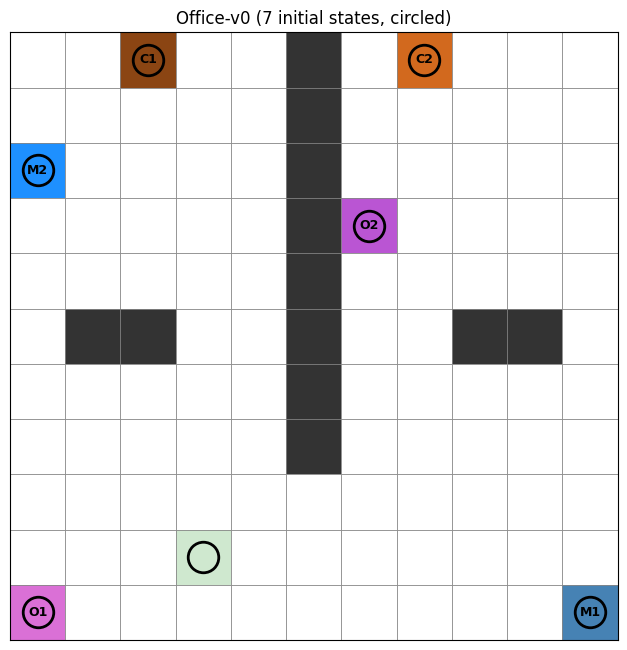

In [5]:
MAP = office_env.core.MAP
height, width = MAP.shape

color_map = {"X": "#333333", "_": "#cfe8cf", " ": "#ffffff"}
object_colors = {
    "C1": "#8B4513", "C2": "#D2691E",
    "M1": "#4682B4", "M2": "#1E90FF",
    "O1": "#DA70D6", "O2": "#BA55D3",
}
color_map.update(object_colors)


def cell_center(r, c):
    return c + 0.5, height - r - 1 + 0.5


def draw_domain(ax):
    for r in range(height):
        for c in range(width):
            sym = MAP[r, c]
            color = color_map.get(sym, "#ffffff")
            rect = mpatches.Rectangle((c, height - r - 1), 1, 1, facecolor=color, edgecolor="gray", linewidth=0.5)
            ax.add_patch(rect)
            if sym not in ("X", " ", "_"):
                ax.text(*cell_center(r, c), sym, ha="center", va="center", fontsize=9, fontweight="bold")
    ax.set_xlim(0, width)
    ax.set_ylim(0, height)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")


fig, ax = plt.subplots(figsize=(width * 0.6, height * 0.6))
draw_domain(ax)
for s in office_env.core.initial:
    x, y = cell_center(*s)
    ax.plot(x, y, marker="o", markersize=22, markerfacecolor="none", markeredgecolor="black", markeredgewidth=2, zorder=5)
ax.set_title(f"Office-v0 ({len(office_env.core.initial)} initial states, circled)")
plt.tight_layout()
plt.show()

In [6]:
ACTIONS = {
    office_env.core.LEFT: "LEFT",
    office_env.core.UP: "UP",
    office_env.core.RIGHT: "RIGHT",
    office_env.core.DOWN: "DOWN",
}
print("Action space:", ACTIONS)

print("\nInitial-state distribution (uniform over these, one drawn per reset()):")
for s in office_env.core.initial:
    print(f"  {s}  ({MAP[s]!r})")


def demo_step(start_state, action):
    obs, info = office_env.reset(options={"state": start_state})
    obs, reward, terminated, truncated, info = office_env.step(action)
    print(f"\nstart={start_state}  action={ACTIONS[action]}"
          f"\n  -> new state={tuple(office_env.core.state)}  reward(phi)={reward}"
          f"\n  -> terminated={terminated}  proposition={info['proposition']!r}")


# 1. A plain move: nothing special, just S -> S' under P
demo_step(start_state=(9, 3), action=office_env.core.UP)

# 2. A wall bump: (0,4) --RIGHT--> (0,5) is 'X', so P self-loops back to (0,4)
demo_step(start_state=(0, 4), action=office_env.core.RIGHT)

# 3. Landing on an object: (0,1) --RIGHT--> (0,2) is 'C1' -> reward fires, episode ends
demo_step(start_state=(0, 1), action=office_env.core.RIGHT)

Action space: {0: 'LEFT', 1: 'UP', 2: 'RIGHT', 3: 'DOWN'}

Initial-state distribution (uniform over these, one drawn per reset()):
  (2, 0)  ('M2')
  (10, 0)  ('O1')
  (0, 2)  ('C1')
  (9, 3)  ('_')
  (3, 6)  ('O2')
  (0, 7)  ('C2')
  (10, 10)  ('M1')

start=(9, 3)  action=UP
  -> new state=(8, 3)  reward(phi)=[0. 0. 0. 0. 0. 0.]
  -> terminated=False  proposition=' '

start=(0, 4)  action=RIGHT
  -> new state=(0, 4)  reward(phi)=[0. 0. 0. 0. 0. 0.]
  -> terminated=False  proposition=' '

start=(0, 1)  action=RIGHT
  -> new state=(0, 2)  reward(phi)=[1. 0. 0. 0. 0. 0.]
  -> terminated=True  proposition='C1'


In [7]:
import random

class SFTable:
    def __init__(self, num_actions, feat_dim, default_vec):
        self.default_vec = default_vec
        self.table = {}

    def __getitem__(self, state):
        if state not in self.table:
            self.table[state] = self.default_vec.copy()
        return self.table[state]


def gpi_action(rng, state, w, sf_tables):
    values = np.stack([sft[state] @ w for sft in sf_tables], axis=0)
    action_values = values.max(axis=0)
    max_val = action_values.max()
    candidates = np.flatnonzero(np.isclose(action_values, max_val))
    return int(rng.choice(candidates))


NUM_STEPS_PER_POLICY = 100_000

def solve_task(env, w, num_steps=NUM_STEPS_PER_POLICY, alpha=0.1, gamma=GAMMA,
               eps_start=1.0, eps_end=0.05, seed=0):
    rng = random.Random(seed)
    n_actions = env.action_space.n
    feat_dim = env.reward_dim

    # one-hot on argmax(w): a tight optimistic upper bound since Office's features are
    # mutually exclusive (touching any object ends the episode).
    optimistic_vec = np.zeros(feat_dim, dtype=np.float32)
    optimistic_vec[np.argmax(w)] = 1.0
    default_vec = np.tile(optimistic_vec, (n_actions, 1))
    psi = SFTable(n_actions, feat_dim, default_vec)

    obs, _ = env.reset()
    state = tuple(env.core.state)
    for t in range(num_steps):
        eps = max(eps_end, eps_start - (eps_start - eps_end) * t / (0.5 * num_steps))
        if rng.random() < eps:
            action = rng.randrange(n_actions)
        else:
            action = gpi_action(rng, state, w, [psi])

        _, phi, terminated, truncated, _ = env.step(action)
        next_state = tuple(env.core.state)

        if terminated:
            target = phi
        else:
            a_prime = gpi_action(rng, next_state, w, [psi])
            target = phi + gamma * psi[next_state][a_prime]
        psi[state][action] += alpha * (target - psi[state][action])

        if terminated or truncated:
            obs, _ = env.reset()
            state = tuple(env.core.state)
        else:
            state = next_state
    return psi


def expected_sf(psi_table, w, initial_states):
    vecs = [psi_table[tuple(s0)][np.argmax(psi_table[tuple(s0)] @ w)] for s0 in initial_states]
    return np.mean(vecs, axis=0)


def new_policy(env, w, num_steps=NUM_STEPS_PER_POLICY, seed=0):
    psi_table = solve_task(env, w, num_steps=num_steps, seed=seed)
    psi_w = expected_sf(psi_table, w, env.core.initial)
    return psi_table, psi_w

d = office_env.reward_dim
simplex_corner_weights = [np.eye(d)[i] for i in range(d)]
w_uniform = np.full(d, 1 / d, dtype=np.float32)

Pi_corners, Psi_corners = [], []
for i, w in enumerate(simplex_corner_weights):
    pi_w, psi_w = new_policy(office_env, w, num_steps=NUM_STEPS_PER_POLICY, seed=SEED + i)
    Pi_corners.append(pi_w)
    Psi_corners.append(psi_w)
    print(f"corner {i} ({PHI_OBJ_TYPES[i]})  w={w}  psi={psi_w.round(3)}  value={np.dot(psi_w, w):.3f}")

corner 0 (C1)  w=[1. 0. 0. 0. 0. 0.]  psi=[0.899 0.    0.    0.    0.    0.   ]  value=0.899


corner 1 (C2)  w=[0. 1. 0. 0. 0. 0.]  psi=[0.   0.89 0.   0.   0.   0.  ]  value=0.890


corner 2 (O1)  w=[0. 0. 1. 0. 0. 0.]  psi=[0.    0.    0.921 0.    0.    0.   ]  value=0.921


corner 3 (O2)  w=[0. 0. 0. 1. 0. 0.]  psi=[0.    0.    0.    0.912 0.    0.   ]  value=0.912


corner 4 (M1)  w=[0. 0. 0. 0. 1. 0.]  psi=[0.    0.    0.    0.    0.903 0.   ]  value=0.903


corner 5 (M2)  w=[0. 0. 0. 0. 0. 1.]  psi=[0.    0.    0.    0.    0.    0.904]  value=0.904


psi_uniform=[0.143 0.143 0.281 0.143 0.143 0.143]  value=0.166


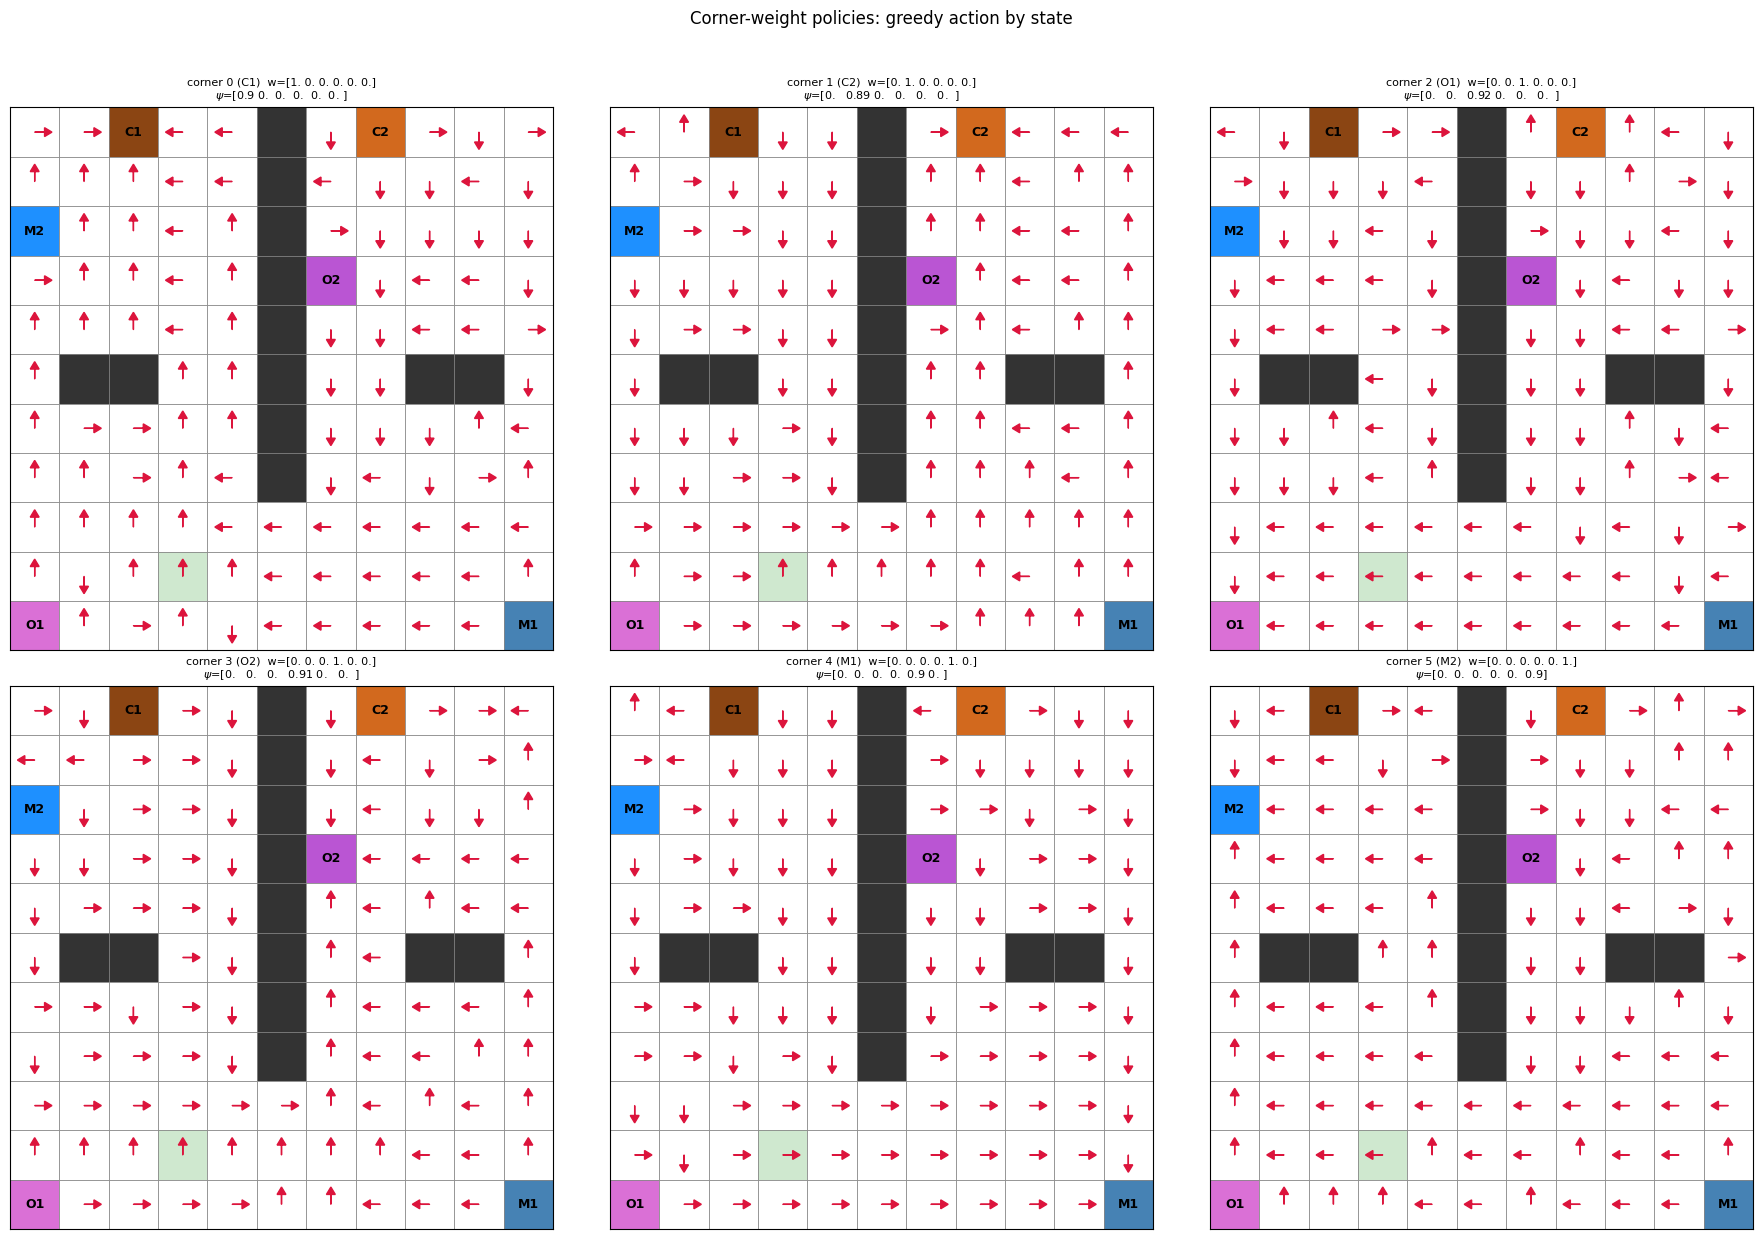

In [8]:
ACTION_DELTAS = {
    office_env.core.LEFT: (-1, 0),
    office_env.core.RIGHT: (1, 0),
    office_env.core.UP: (0, 1),
    office_env.core.DOWN: (0, -1),
}


def plot_policy_arrows(ax, psi_table, w, arrow_len=0.35):
    draw_domain(ax)
    for r in range(height):
        for c in range(width):
            if MAP[r, c] not in (" ", "_"):
                continue
            state = (r, c)
            action = int(np.argmax(psi_table[state] @ w))
            dcol, drow = ACTION_DELTAS[action]
            x, y = cell_center(r, c)
            ax.arrow(x, y, dcol * arrow_len, drow * arrow_len, head_width=0.18, head_length=0.15,
                      fc="crimson", ec="crimson", length_includes_head=True, zorder=6)

pi_uniform, psi_uniform = new_policy(office_env, w_uniform, num_steps=NUM_STEPS_PER_POLICY, seed=SEED + 100)
print(f"psi_uniform={psi_uniform.round(3)}  value={np.dot(psi_uniform, w_uniform):.3f}")

fig, axes = plt.subplots(2, 3, figsize=(width * 0.55 * 3, height * 0.55 * 2))
axes = axes.reshape(-1)

for i, ax in enumerate(axes):
    plot_policy_arrows(ax, Pi_corners[i], simplex_corner_weights[i])
    ax.set_title(f"corner {i} ({PHI_OBJ_TYPES[i]})  w={simplex_corner_weights[i]}\n"
                 + r"$\psi$=" + f"{Psi_corners[i].round(2)}", fontsize=8)

fig.suptitle("Corner-weight policies: greedy action by state", y=1.02)
plt.tight_layout()
plt.show()

In [9]:
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F


class MetaPolicy(nn.Module):
    def __init__(self, state_dim, task_dim, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(state_dim + task_dim, hidden), nn.ReLU(),
                                  nn.Linear(hidden, hidden), nn.ReLU(),
                                  nn.Linear(hidden, task_dim))
    def logits(self, s, w):
        return self.net(torch.cat([s, w], dim=-1))
    def forward(self, s, w):
        return F.softmax(self.logits(s, w), dim=-1)

class MetaCritic(nn.Module):
    def __init__(self, state_dim, task_dim, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(state_dim + 2 * task_dim, hidden), nn.ReLU(),
                                  nn.Linear(hidden, hidden), nn.ReLU(),
                                  nn.Linear(hidden, task_dim))
    def forward(self, s, z, w):
        return self.net(torch.cat([s, z, w], dim=-1))


class ReplayBuffer:
    def __init__(self, capacity, state_dim, task_dim):
        self.s = np.zeros((capacity, state_dim), dtype=np.float32)
        self.z = np.zeros((capacity, task_dim), dtype=np.float32)
        self.phi = np.zeros((capacity, task_dim), dtype=np.float32)
        self.s_next = np.zeros((capacity, state_dim), dtype=np.float32)
        self.done = np.zeros((capacity,), dtype=np.float32)
        self.capacity, self.ptr, self.size = capacity, 0, 0

    def add(self, s, z, phi, s_next, done):
        i = self.ptr
        self.s[i], self.z[i], self.phi[i] = s, z, phi
        self.s_next[i], self.done[i] = s_next, float(done)
        self.ptr = (self.ptr + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size, rng):
        idx = rng.integers(0, self.size, size=batch_size)
        return self.s[idx], self.z[idx], self.phi[idx], self.s_next[idx], self.done[idx]

In [10]:
def train_ok(env, omega, psi_omega, W_sup, Pi_base, eval_env=None, num_steps=2_000, batch_size=512,
             gamma=GAMMA, actor_lr=3e-4, critic_lr=1e-3, buffer_capacity=30_000,
             noise_std_start=2.0, noise_std_end=0.1, noise_decay_frac=1.0,
             tau=0.005, policy_delay=2, target_noise_std=0.5, seed=0,
             min_iter=30_000, critic_warmup_steps=20_000, eval_interval=1000):
    rng = np.random.default_rng(seed)
    py_rng = random.Random(seed)
    eval_env = env if eval_env is None else eval_env
    task_dim = env.reward_dim
    state_dim = 2
    buffer = ReplayBuffer(buffer_capacity, state_dim, task_dim)
    W_sup_arr = np.stack(W_sup).astype(np.float32)

    core_map = env.core.MAP
    all_states = [(r, c) for r in range(core_map.shape[0]) for c in range(core_map.shape[1]) if core_map[r, c] != "X"]

    def random_reset():
        obs, _ = env.reset(options={"state": all_states[py_rng.randrange(len(all_states))]})
        return obs

    def eval_omega(omega_net, w_eval, max_steps=200):
        # runs on a *separate* env instance -- the training loop below tracks its own
        # obs/state across iterations rather than re-querying env each step, so reusing
        # `env` here would silently desync it mid-episode.
        w_t_eval = torch.as_tensor(w_eval, dtype=torch.float32).unsqueeze(0)
        total = 0.0
        for s0 in eval_env.core.initial:
            o, _ = eval_env.reset(options={"state": s0})
            s = tuple(eval_env.core.state)
            disc, ret = 1.0, 0.0
            for _ in range(max_steps):
                with torch.no_grad():
                    z = omega_net(torch.as_tensor(o).unsqueeze(0), w_t_eval).squeeze(0).numpy()
                a = gpi_action(py_rng, s, z, Pi_base)
                o, phi, term, trunc, _ = eval_env.step(a)
                s = tuple(eval_env.core.state)
                ret += disc * float(np.dot(phi, w_eval))
                disc *= gamma
                if term or trunc:
                    break
            total += ret
        return total / len(eval_env.core.initial)

    omega_t, psi_t = copy.deepcopy(omega), copy.deepcopy(psi_omega)
    for p in omega_t.parameters(): p.requires_grad_(False)
    for p in psi_t.parameters(): p.requires_grad_(False)

    actor_opt = torch.optim.Adam(omega.parameters(), lr=actor_lr)
    critic_opt = torch.optim.Adam(psi_omega.parameters(), lr=critic_lr)

    def sample_w(n):
        return W_sup_arr[rng.integers(len(W_sup_arr), size=n)]

    actor_steps = num_steps - critic_warmup_steps

    w_t = sample_w(1)[0]
    obs = random_reset()
    state = tuple(env.core.state)
    losses, value_snapshots, eval_snapshots = [], [], []
    track_states = [torch.as_tensor(env._normalize(s0)).unsqueeze(0) for s0 in env.core.initial]
    track_w = torch.as_tensor(W_sup_arr[0]).unsqueeze(0)
    best_val, best_state = -np.inf, None

    for t in range(num_steps):
        if t > 0 and (terminated or truncated):
            w_t = sample_w(1)[0]
            obs = random_reset()
            state = tuple(env.core.state)

        if t < critic_warmup_steps:
            noise_std = noise_std_start
        else:
            t_since_warmup = t - critic_warmup_steps
            noise_std = max(noise_std_end, noise_std_start - (noise_std_start - noise_std_end) * t_since_warmup / (noise_decay_frac * actor_steps))
        with torch.no_grad():
            logits = omega.logits(torch.as_tensor(obs).unsqueeze(0), torch.as_tensor(w_t).unsqueeze(0)).squeeze(0).numpy()
        logits = logits + rng.normal(0, noise_std, task_dim)
        z = F.softmax(torch.as_tensor(logits, dtype=torch.float32), dim=-1).numpy()

        action = gpi_action(py_rng, state, z, Pi_base)
        next_obs, phi, terminated, truncated, _ = env.step(action)
        next_state = tuple(env.core.state)
        buffer.add(obs, z, phi, next_obs, terminated)
        obs, state = next_obs, next_state

        if buffer.size >= batch_size:
            s_b, z_b, phi_b, s_next_b, done_b = buffer.sample(batch_size, rng)
            w_b = torch.as_tensor(sample_w(batch_size))
            s_b, z_b, phi_b, s_next_b = (torch.as_tensor(x) for x in (s_b, z_b, phi_b, s_next_b))
            done_b = torch.as_tensor(done_b).unsqueeze(-1)

            with torch.no_grad():
                logits_next = omega_t.logits(s_next_b, w_b)
                logits_next = logits_next + torch.clamp(torch.randn_like(logits_next) * target_noise_std, -1.0, 1.0)
                z_next = F.softmax(logits_next, dim=-1)
                target = phi_b + gamma * (1 - done_b) * psi_t(s_next_b, z_next, w_b)

            critic_loss = F.mse_loss(psi_omega(s_b, z_b, w_b), target)
            critic_opt.zero_grad(); critic_loss.backward(); critic_opt.step()

            if t >= min_iter and t % eval_interval == 0:
                val = eval_omega(omega, W_sup_arr[0])
                eval_snapshots.append((t, val))
                if val > best_val:
                    best_val = val
                    best_state = (copy.deepcopy(omega.state_dict()), copy.deepcopy(psi_omega.state_dict()), t, best_val)

            if t % 100 == 0:
                losses.append(critic_loss.item())
                with torch.no_grad():
                    vs = [(psi_omega(s, omega(s, track_w), track_w) * track_w).sum().item() for s in track_states]
                value_snapshots.append(np.mean(vs))

            if t % policy_delay == 0:
                with torch.no_grad():
                    for p, tp in zip(psi_omega.parameters(), psi_t.parameters()):
                        tp.data.mul_(1 - tau).add_(tau * p.data)

                if t >= critic_warmup_steps:
                    z_pi = omega(s_b, w_b)
                    actor_loss = -(psi_omega(s_b, z_pi, w_b) * w_b).sum(-1).mean()
                    actor_opt.zero_grad(); actor_loss.backward(); actor_opt.step()
                    with torch.no_grad():
                        for p, tp in zip(omega.parameters(), omega_t.parameters()):
                            tp.data.mul_(1 - tau).add_(tau * p.data)
    if best_state is None:
        # num_steps (2_000 by default) never reached min_iter (30_000), so the eval
        # branch above never ran and best_state was never set -- fall back to the final
        # checkpoint instead of returning None (downstream cells unpack best_state[0:4]
        # unconditionally).
        best_state = (copy.deepcopy(omega.state_dict()), copy.deepcopy(psi_omega.state_dict()),
                      num_steps, float("nan"))
    return omega, psi_omega, losses, value_snapshots, eval_snapshots, best_state


torch.manual_seed(SEED)
w_uniform = np.full(d, 1 / d, dtype=np.float32)
w_uniform = np.array([1.0, 0.0, 0.0, 0.0, 0.0, 0.0], dtype=np.float32)
omega = MetaPolicy(2, d)
psi_omega = MetaCritic(2, d)
omega, psi_omega, losses, value_snapshots, eval_snapshots, best_state = train_ok(
    office_env, omega, psi_omega, [w_uniform], Pi_corners, eval_env=office_eval_env, seed=SEED)


def ok_action(rng, state, obs, w, omega, sf_tables):
    with torch.no_grad():
        z = omega(torch.as_tensor(obs).unsqueeze(0), torch.as_tensor(w).unsqueeze(0)).squeeze(0).numpy()
    return gpi_action(rng, state, z, sf_tables)


def rollout_value(env, action_fn, start_state, w, gamma=GAMMA, max_steps=200):
    obs, _ = env.reset(options={"state": start_state})
    state = tuple(env.core.state)
    total, disc = 0.0, 1.0
    for _ in range(max_steps):
        action = action_fn(state, obs)
        obs, phi, terminated, truncated, _ = env.step(action)
        state = tuple(env.core.state)
        total += disc * float(np.dot(phi, w))
        disc *= gamma
        if terminated or truncated:
            break
    return total


rng_eval = random.Random(SEED + 1)
starts = office_env.core.initial
ok_val = np.mean([rollout_value(office_env, lambda s, o: ok_action(rng_eval, s, o, w_uniform, omega, Pi_corners), s0, w_uniform) for s0 in starts])
gpi_val = np.mean([rollout_value(office_env, lambda s, o: gpi_action(rng_eval, s, w_uniform, Pi_corners), s0, w_uniform) for s0 in starts])
print(f"ok_meta_policy={ok_val:.4f}  gpi_over_corners={gpi_val:.4f}")


ok_meta_policy=0.0000  gpi_over_corners=0.8988


In [11]:
class MetaPolicyBig(nn.Module):
    # paper's stated ω architecture: MLP, 3 hidden layers of 256 units
    def __init__(self, state_dim, task_dim, hidden=256):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(state_dim + task_dim, hidden), nn.ReLU(),
                                  nn.Linear(hidden, hidden), nn.ReLU(),
                                  nn.Linear(hidden, hidden), nn.ReLU(),
                                  nn.Linear(hidden, task_dim))
    def logits(self, s, w):
        return self.net(torch.cat([s, w], dim=-1))
    def forward(self, s, w):
        return F.softmax(self.logits(s, w), dim=-1)


class MetaCriticBN(nn.Module):
    # same 3x256 sizing, plus BatchNorm -- the Bhatt et al. (2024) "CrossQ" technique the
    # paper cites, which is what lets train_ok_crossq below drop the target critic entirely.
    def __init__(self, state_dim, task_dim, hidden=256):
        super().__init__()
        self.fc1 = nn.Linear(state_dim + 2 * task_dim, hidden)
        self.bn1 = nn.BatchNorm1d(hidden)
        self.fc2 = nn.Linear(hidden, hidden)
        self.bn2 = nn.BatchNorm1d(hidden)
        self.fc3 = nn.Linear(hidden, hidden)
        self.bn3 = nn.BatchNorm1d(hidden)
        self.fc4 = nn.Linear(hidden, task_dim)

    def forward(self, s, z, w):
        x = torch.cat([s, z, w], dim=-1)
        x = F.relu(self.bn1(self.fc1(x)))
        x = F.relu(self.bn2(self.fc2(x)))
        x = F.relu(self.bn3(self.fc3(x)))
        return self.fc4(x)


def train_ok_crossq(env, omega, psi_omega, W_sup, Pi_base, eval_env=None, num_steps=2_000, batch_size=256,
                     gamma=GAMMA, actor_lr=3e-4, critic_lr=1e-3, buffer_capacity=10_000,
                     noise_std_start=2.0, noise_std_end=0.1, noise_decay_frac=1.0,
                     policy_delay=2, target_noise_std=0.5, seed=0,
                     min_iter=30_000, critic_warmup_steps=20_000, eval_interval=1000):
    # CrossQ (Bhatt et al. 2024): no target networks -- BatchNorm sees current+next
    # (s,z,w) batches in one forward pass, stabilizing TD bootstrapping without them.
    rng = np.random.default_rng(seed)
    py_rng = random.Random(seed)
    eval_env = env if eval_env is None else eval_env
    task_dim = env.reward_dim
    state_dim = 2
    buffer = ReplayBuffer(buffer_capacity, state_dim, task_dim)
    W_sup_arr = np.stack(W_sup).astype(np.float32)

    core_map = env.core.MAP
    all_states = [(r, c) for r in range(core_map.shape[0]) for c in range(core_map.shape[1]) if core_map[r, c] != "X"]

    def random_reset():
        obs, _ = env.reset(options={"state": all_states[py_rng.randrange(len(all_states))]})
        return obs

    def eval_omega(omega_net, w_eval, max_steps=200):
        w_t_eval = torch.as_tensor(w_eval, dtype=torch.float32).unsqueeze(0)
        total = 0.0
        for s0 in eval_env.core.initial:
            o, _ = eval_env.reset(options={"state": s0})
            s = tuple(eval_env.core.state)
            disc, ret = 1.0, 0.0
            for _ in range(max_steps):
                with torch.no_grad():
                    z = omega_net(torch.as_tensor(o).unsqueeze(0), w_t_eval).squeeze(0).numpy()
                a = gpi_action(py_rng, s, z, Pi_base)
                o, phi, term, trunc, _ = eval_env.step(a)
                s = tuple(eval_env.core.state)
                ret += disc * float(np.dot(phi, w_eval))
                disc *= gamma
                if term or trunc:
                    break
            total += ret
        return total / len(eval_env.core.initial)

    actor_opt = torch.optim.Adam(omega.parameters(), lr=actor_lr)
    critic_opt = torch.optim.Adam(psi_omega.parameters(), lr=critic_lr)

    def sample_w(n):
        return W_sup_arr[rng.integers(len(W_sup_arr), size=n)]

    actor_steps = num_steps - critic_warmup_steps

    w_t = sample_w(1)[0]
    obs = random_reset()
    state = tuple(env.core.state)
    losses, value_snapshots, eval_snapshots = [], [], []
    track_states = [torch.as_tensor(env._normalize(s0)).unsqueeze(0) for s0 in env.core.initial]
    track_w = torch.as_tensor(W_sup_arr[0]).unsqueeze(0)
    best_val, best_state = -np.inf, None

    for t in range(num_steps):
        if t > 0 and (terminated or truncated):
            w_t = sample_w(1)[0]
            obs = random_reset()
            state = tuple(env.core.state)

        if t < critic_warmup_steps:
            noise_std = noise_std_start
        else:
            t_since_warmup = t - critic_warmup_steps
            noise_std = max(noise_std_end, noise_std_start - (noise_std_start - noise_std_end) * t_since_warmup / (noise_decay_frac * actor_steps))
        with torch.no_grad():
            logits = omega.logits(torch.as_tensor(obs).unsqueeze(0), torch.as_tensor(w_t).unsqueeze(0)).squeeze(0).numpy()
        logits = logits + rng.normal(0, noise_std, task_dim)
        z = F.softmax(torch.as_tensor(logits, dtype=torch.float32), dim=-1).numpy()

        action = gpi_action(py_rng, state, z, Pi_base)
        next_obs, phi, terminated, truncated, _ = env.step(action)
        next_state = tuple(env.core.state)
        buffer.add(obs, z, phi, next_obs, terminated)
        obs, state = next_obs, next_state

        if buffer.size >= batch_size:
            s_b, z_b, phi_b, s_next_b, done_b = buffer.sample(batch_size, rng)
            w_b = torch.as_tensor(sample_w(batch_size))
            s_b, z_b, phi_b, s_next_b = (torch.as_tensor(x) for x in (s_b, z_b, phi_b, s_next_b))
            done_b = torch.as_tensor(done_b).unsqueeze(-1)

            # target-policy smoothing around the live actor (no separate omega_t)
            with torch.no_grad():
                logits_next = omega.logits(s_next_b, w_b)
                logits_next = logits_next + torch.clamp(torch.randn_like(logits_next) * target_noise_std, -1.0, 1.0)
                z_next = F.softmax(logits_next, dim=-1)

            # CrossQ trick: one joint forward pass over [current; next] so BatchNorm sees
            # both distributions together, instead of bootstrapping off a separate target
            psi_omega.train()
            s_cat = torch.cat([s_b, s_next_b], dim=0)
            z_cat = torch.cat([z_b, z_next], dim=0)
            w_cat = torch.cat([w_b, w_b], dim=0)
            pred_cat = psi_omega(s_cat, z_cat, w_cat)
            pred, next_pred = pred_cat[:batch_size], pred_cat[batch_size:]
            target = phi_b + gamma * (1 - done_b) * next_pred.detach()

            critic_loss = F.mse_loss(pred, target)
            critic_opt.zero_grad(); critic_loss.backward(); critic_opt.step()

            if t >= min_iter and t % eval_interval == 0:
                psi_omega.eval()
                val = eval_omega(omega, W_sup_arr[0])
                psi_omega.train()
                eval_snapshots.append((t, val))
                if val > best_val:
                    best_val = val
                    best_state = (copy.deepcopy(omega.state_dict()), copy.deepcopy(psi_omega.state_dict()), t, best_val)

            if t % 100 == 0:
                losses.append(critic_loss.item())
                psi_omega.eval()
                with torch.no_grad():
                    vs = [(psi_omega(s, omega(s, track_w), track_w) * track_w).sum().item() for s in track_states]
                psi_omega.train()
                value_snapshots.append(np.mean(vs))

            if t % policy_delay == 0:
                z_pi = omega(s_b, w_b)
                actor_loss = -(psi_omega(s_b, z_pi, w_b) * w_b).sum(-1).mean()
                actor_opt.zero_grad(); actor_loss.backward(); actor_opt.step()

    psi_omega.eval()  # so downstream single-sample calls (value_map, ok_action, ...) work
    if best_state is None:
        # num_steps (2_000 by default) never reached min_iter (30_000), so the eval
        # branch above never ran and best_state was never set -- fall back to the final
        # checkpoint instead of returning None (downstream cells unpack best_state[0:4]
        # unconditionally).
        best_state = (copy.deepcopy(omega.state_dict()), copy.deepcopy(psi_omega.state_dict()),
                      num_steps, float("nan"))
    return omega, psi_omega, losses, value_snapshots, eval_snapshots, best_state


torch.manual_seed(SEED)
w_uniform = np.full(d, 1 / d, dtype=np.float32)
omega = MetaPolicyBig(2, d)
psi_omega = MetaCriticBN(2, d)
omega, psi_omega, losses, value_snapshots, eval_snapshots, best_state = train_ok_crossq(
    office_env, omega, psi_omega, [w_uniform], Pi_corners, eval_env=office_eval_env, seed=SEED)


def ok_action(rng, state, obs, w, omega, sf_tables):
    with torch.no_grad():
        z = omega(torch.as_tensor(obs).unsqueeze(0), torch.as_tensor(w).unsqueeze(0)).squeeze(0).numpy()
    return gpi_action(rng, state, z, sf_tables)


def rollout_value(env, action_fn, start_state, w, gamma=GAMMA, max_steps=200):
    obs, _ = env.reset(options={"state": start_state})
    state = tuple(env.core.state)
    total, disc = 0.0, 1.0
    for _ in range(max_steps):
        action = action_fn(state, obs)
        obs, phi, terminated, truncated, _ = env.step(action)
        state = tuple(env.core.state)
        total += disc * float(np.dot(phi, w))
        disc *= gamma
        if terminated or truncated:
            break
    return total


rng_eval = random.Random(SEED + 1)
starts = office_env.core.initial
ok_val = np.mean([rollout_value(office_env, lambda s, o: ok_action(rng_eval, s, o, w_uniform, omega, Pi_corners), s0, w_uniform) for s0 in starts])
gpi_val = np.mean([rollout_value(office_env, lambda s, o: gpi_action(rng_eval, s, w_uniform, Pi_corners), s0, w_uniform) for s0 in starts])
print(f"ok_meta_policy_crossq={ok_val:.4f}  gpi_over_corners={gpi_val:.4f}")


ok_meta_policy_crossq=0.0000  gpi_over_corners=0.1660


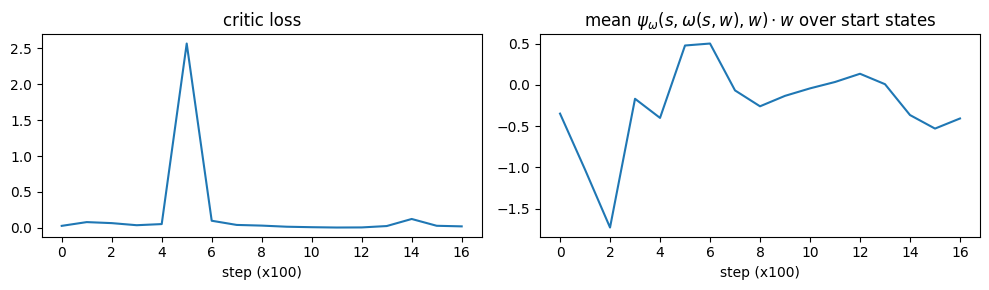

-0.4068263236965452


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(losses)
axes[0].set_xlabel("step (x100)")
axes[0].set_title("critic loss")
axes[1].plot(value_snapshots)
axes[1].set_xlabel("step (x100)")
axes[1].set_title(r"mean $\psi_\omega(s,\omega(s,w),w)\cdot w$ over start states")
plt.tight_layout()
plt.show()

print(value_snapshots[-1])

In [13]:
omega_best, psi_omega_best = copy.deepcopy(omega), copy.deepcopy(psi_omega)
omega_best.load_state_dict(best_state[0])
psi_omega_best.load_state_dict(best_state[1])
psi_omega_best.eval()
print(f"best checkpoint: step={best_state[2]}  eval_return={best_state[3]:.4f}")

best_val = np.mean([rollout_value(office_env, lambda s, o: ok_action(rng_eval, s, o, w_uniform, omega_best, Pi_corners), s0, w_uniform) for s0 in starts])
print(f"ok_policy_best={best_val:.4f}  ok_policy_final={ok_val:.4f}  gpi_over_corners={gpi_val:.4f}")

best checkpoint: step=2000  eval_return=nan


ok_policy_best=0.0000  ok_policy_final=0.0000  gpi_over_corners=0.1660


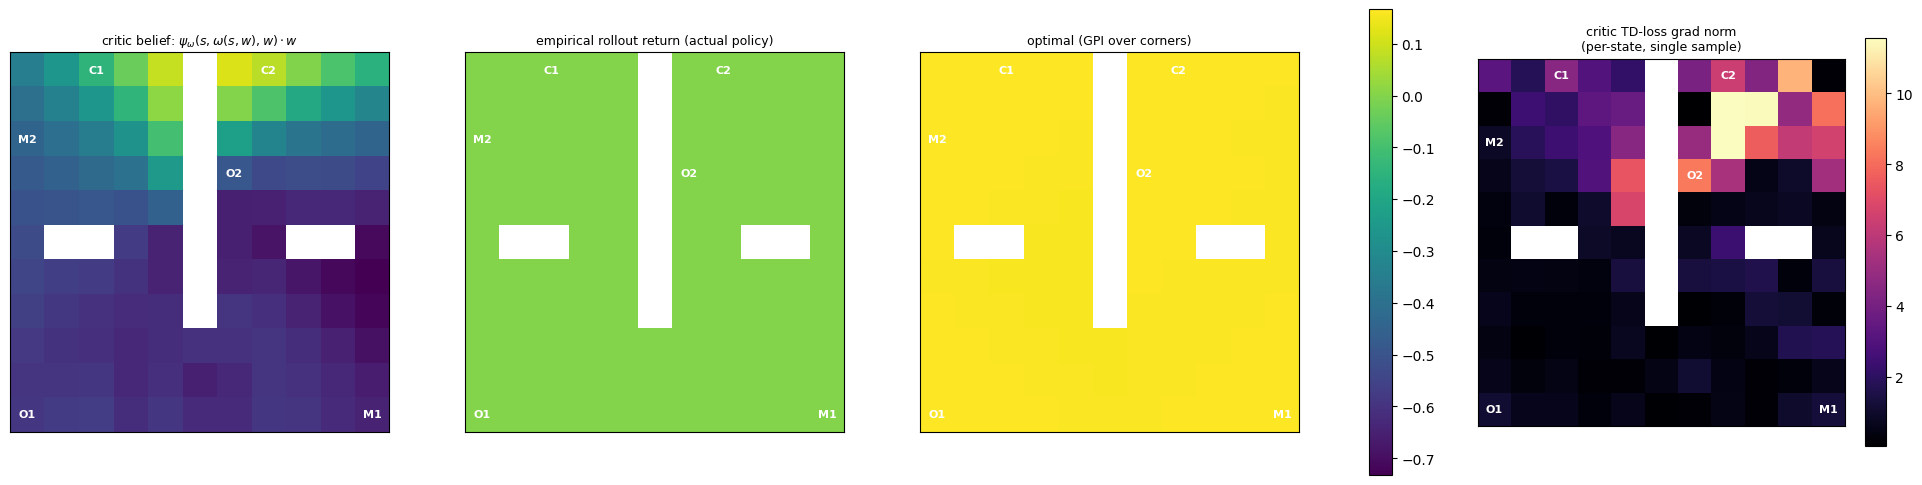

mean |critic belief - empirical|  = 0.4916   (critic calibration error)
mean |empirical - optimal|        = 0.1630   (actual policy suboptimality)
corr(suboptimality gap, critic grad norm) = 0.247


In [14]:
def value_map(w):
    w_t = torch.as_tensor(w, dtype=torch.float32).unsqueeze(0)
    vals = np.full((height, width), np.nan)
    for r in range(height):
        for c in range(width):
            if MAP[r, c] == "X":
                continue
            s_t = torch.as_tensor(office_env._normalize((r, c))).unsqueeze(0)
            with torch.no_grad():
                z = omega(s_t, w_t)
                vals[r, c] = (psi_omega(s_t, z, w_t) * w_t).sum().item()
    return vals


def empirical_value_map(w):
    # actual Monte-Carlo return from rolling out the trained policy from each state --
    # ground truth to compare against the critic's own belief (value_map) and the optimum.
    vals = np.full((height, width), np.nan)
    for r in range(height):
        for c in range(width):
            if MAP[r, c] == "X":
                continue
            state = (r, c)
            vals[r, c] = rollout_value(office_env, lambda s, o: ok_action(rng_eval, s, o, w, omega, Pi_corners), state, w)
    return vals


def optimal_value_map(w, sf_tables=Pi_corners):
    vals = np.full((height, width), np.nan)
    for r in range(height):
        for c in range(width):
            if MAP[r, c] == "X":
                continue
            state = (r, c)
            vals[r, c] = max((sft[state] @ w).max() for sft in sf_tables)
    return vals


def critic_grad_norm_map(w):
    # per-state critic TD-loss gradient norm: simulate one fresh transition from each
    # state under the current trained policy (on a separate env, same isolation reason
    # as eval_omega), then measure ||d critic_loss / d psi_omega_params|| for just that
    # single sample. Large values mean this state would still pull the critic hard right
    # now; near-zero means the loss has already settled there -- including the degenerate
    # case of a self-consistent but wrong fixed point (phi=0 forever, target=prediction=0).
    w_t = torch.as_tensor(w, dtype=torch.float32).unsqueeze(0)
    vals = np.full((height, width), np.nan)
    for r in range(height):
        for c in range(width):
            if MAP[r, c] == "X":
                continue
            state = (r, c)
            o, _ = office_eval_env.reset(options={"state": state})
            s_t = torch.as_tensor(o, dtype=torch.float32).unsqueeze(0)
            with torch.no_grad():
                z = omega(s_t, w_t)
            a = gpi_action(rng_eval, state, z.squeeze(0).numpy(), Pi_corners)
            o_next, phi, term, trunc, _ = office_eval_env.step(a)
            s_next_t = torch.as_tensor(o_next, dtype=torch.float32).unsqueeze(0)
            phi_t = torch.as_tensor(phi, dtype=torch.float32).unsqueeze(0)
            done_t = torch.tensor([[float(term)]])

            with torch.no_grad():
                z_next = omega(s_next_t, w_t)
                target = phi_t + GAMMA * (1 - done_t) * psi_omega(s_next_t, z_next, w_t)

            psi_omega.zero_grad()
            loss = F.mse_loss(psi_omega(s_t, z, w_t), target)
            loss.backward()
            vals[r, c] = sum(p.grad.pow(2).sum().item() for p in psi_omega.parameters() if p.grad is not None) ** 0.5
    psi_omega.zero_grad()
    return vals


vals = value_map(w_uniform)
emp_vals = empirical_value_map(w_uniform)
opt_vals = optimal_value_map(w_uniform)
grad_vals = critic_grad_norm_map(w_uniform)
vmin, vmax = np.nanmin([vals, emp_vals, opt_vals]), np.nanmax([vals, emp_vals, opt_vals])

fig, axes = plt.subplots(1, 4, figsize=(width * 0.55 * 4, height * 0.55))
for ax, v, title in zip(axes[:3], [vals, emp_vals, opt_vals],
                         [r"critic belief: $\psi_\omega(s,\omega(s,w),w)\cdot w$",
                          "empirical rollout return (actual policy)",
                          "optimal (GPI over corners)"]):
    im = ax.imshow(v, cmap="viridis", vmin=vmin, vmax=vmax)
    for r in range(height):
        for c in range(width):
            if MAP[r, c] not in (" ", "_", "X"):
                ax.text(c, r, MAP[r, c], ha="center", va="center", fontsize=8, fontweight="bold", color="white")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=9)
fig.colorbar(im, ax=list(axes[:3]), fraction=0.02)

im2 = axes[3].imshow(grad_vals, cmap="magma")
for r in range(height):
    for c in range(width):
        if MAP[r, c] not in (" ", "_", "X"):
            axes[3].text(c, r, MAP[r, c], ha="center", va="center", fontsize=8, fontweight="bold", color="white")
axes[3].set_xticks([])
axes[3].set_yticks([])
axes[3].set_title("critic TD-loss grad norm\n(per-state, single sample)", fontsize=9)
fig.colorbar(im2, ax=axes[3], fraction=0.05)
plt.show()

print(f"mean |critic belief - empirical|  = {np.nanmean(np.abs(vals - emp_vals)):.4f}   (critic calibration error)")
print(f"mean |empirical - optimal|        = {np.nanmean(np.abs(emp_vals - opt_vals)):.4f}   (actual policy suboptimality)")

gap = np.abs(emp_vals - opt_vals)
mask = ~np.isnan(gap)
corr = np.corrcoef(gap[mask], grad_vals[mask])[0, 1]
print(f"corr(suboptimality gap, critic grad norm) = {corr:.3f}")

state=(0, 0)  obs=[0. 0.]  z=[0.001 0.375 0.017 0.577 0.021 0.009]
state=(0, 1)  obs=[0.  0.1]  z=[0.003 0.18  0.024 0.748 0.025 0.02 ]
state=(0, 3)  obs=[0.  0.3]  z=[0.078 0.034 0.034 0.698 0.034 0.121]
state=(0, 4)  obs=[0.  0.4]  z=[0.202 0.013 0.025 0.507 0.026 0.227]
state=(0, 6)  obs=[0.  0.6]  z=[0.34  0.003 0.01  0.336 0.01  0.301]
state=(0, 8)  obs=[0.  0.8]  z=[0.423 0.001 0.004 0.264 0.004 0.304]
state=(0, 9)  obs=[0.  0.9]  z=[0.452 0.    0.003 0.241 0.002 0.301]
state=(0, 10)  obs=[0. 1.]  z=[0.479 0.    0.002 0.222 0.001 0.295]
state=(1, 0)  obs=[0.1 0. ]  z=[0.    0.363 0.011 0.607 0.013 0.006]
state=(1, 1)  obs=[0.1 0.1]  z=[0.002 0.15  0.015 0.805 0.014 0.013]
state=(1, 2)  obs=[0.1 0.2]  z=[0.011 0.053 0.019 0.873 0.015 0.029]
state=(1, 3)  obs=[0.1 0.3]  z=[0.079 0.023 0.025 0.771 0.018 0.085]
state=(1, 4)  obs=[0.1 0.4]  z=[0.279 0.008 0.019 0.495 0.014 0.185]
state=(1, 6)  obs=[0.1 0.6]  z=[0.438 0.001 0.007 0.288 0.005 0.261]
state=(1, 7)  obs=[0.1 0.7]  z=[0.48 

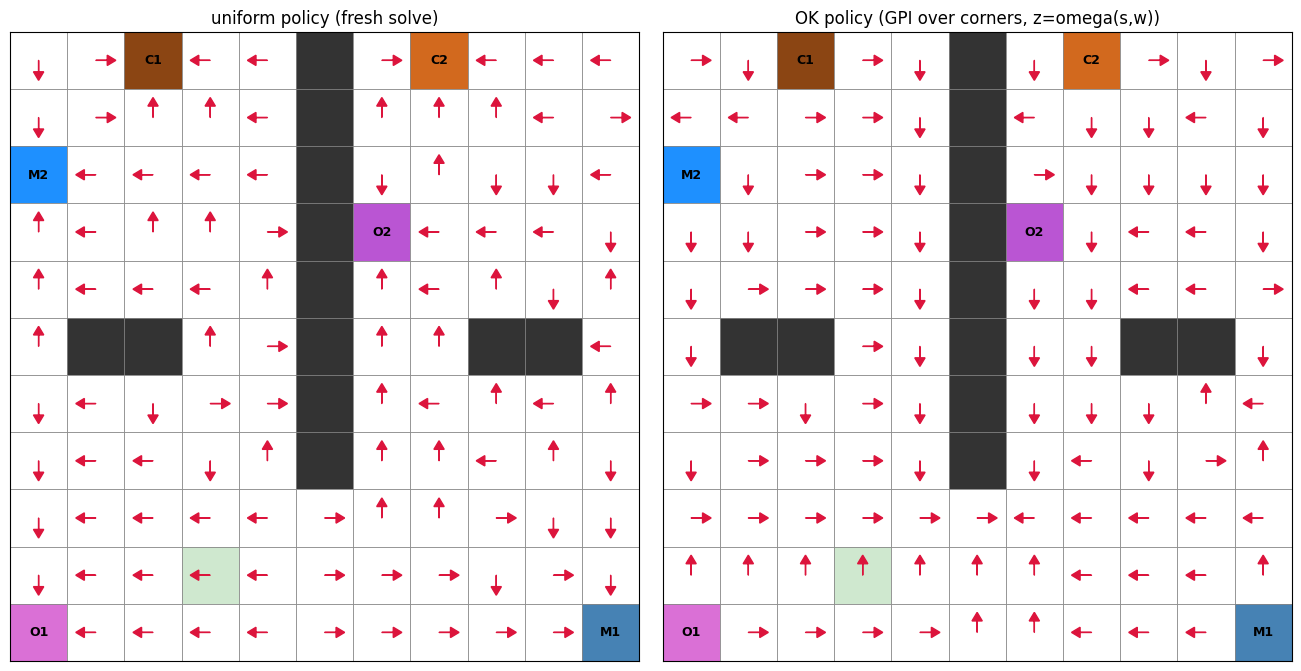

In [15]:
def ok_greedy_action(state):
    obs = office_env._normalize(state)
    with torch.no_grad():
        z = omega(torch.as_tensor(obs).unsqueeze(0), torch.as_tensor(w_uniform).unsqueeze(0)).squeeze(0).numpy()
        print(f"state={state}  obs={obs}  z={z.round(3)}")
    values = np.stack([sft[state] @ z for sft in Pi_corners], axis=0)
    return int(values.max(axis=0).argmax())


def plot_arrows(ax, action_fn, arrow_len=0.35):
    draw_domain(ax)
    for r in range(height):
        for c in range(width):
            if MAP[r, c] not in (" ", "_"):
                continue
            action = action_fn((r, c))
            dcol, drow = ACTION_DELTAS[action]
            x, y = cell_center(r, c)
            ax.arrow(x, y, dcol * arrow_len, drow * arrow_len, head_width=0.18, head_length=0.15,
                      fc="crimson", ec="crimson", length_includes_head=True, zorder=6)


fig, axes = plt.subplots(1, 2, figsize=(width * 0.6 * 2, height * 0.6))
plot_arrows(axes[0], lambda s: int(np.argmax(pi_uniform[s] @ w_uniform)))
axes[0].set_title("uniform policy (fresh solve)")
plot_arrows(axes[1], ok_greedy_action)
axes[1].set_title("OK policy (GPI over corners, z=omega(s,w))")
plt.tight_layout()
plt.show()

In [16]:
uniform_val = np.mean([rollout_value(office_env, lambda s, o: gpi_action(rng_eval, s, w_uniform, [pi_uniform]), s0, w_uniform) for s0 in starts])
ok_val = np.mean([rollout_value(office_env, lambda s, o: ok_action(rng_eval, s, o, w_uniform, omega, Pi_corners), s0, w_uniform) for s0 in starts])
print(f"uniform_policy={uniform_val:.4f}  ok_policy={ok_val:.4f}")

uniform_policy=0.1660  ok_policy=0.0000


In [17]:
OBJECT_POS = [None] * d
for r in range(height):
    for c in range(width):
        sym = MAP[r, c]
        if sym in PHI_OBJ_TYPES:
            OBJECT_POS[PHI_OBJ_TYPES.index(sym)] = (r, c)


def deterministic_omega(state):
    # pure grid (Manhattan) distance from `state` to each object's actual map location --
    # no SF/Pi_corners involved at all, just "which exit is physically nearest".
    dists = [abs(state[0] - r) + abs(state[1] - c) for r, c in OBJECT_POS]
    label = int(np.argmin(dists))
    z = np.zeros(d, dtype=np.float32)
    z[label] = 1.0
    return z


def ok_action_det(rng, state, obs, sf_tables):
    z = deterministic_omega(state)
    return gpi_action(rng, state, z, sf_tables)


det_val = np.mean([rollout_value(office_env, lambda s, o: ok_action_det(rng_eval, s, o, Pi_corners), s0, w_uniform) for s0 in starts])
print(f"deterministic_meta_policy={det_val:.4f}  gpi_over_corners={gpi_val:.4f}\n")

for s in starts:
    z = deterministic_omega(s)
    print(f"  state={s} ({MAP[s]!r})  nearest={PHI_OBJ_TYPES[int(z.argmax())]}")

deterministic_meta_policy=0.1660  gpi_over_corners=0.1660

  state=(2, 0) ('M2')  nearest=M2
  state=(10, 0) ('O1')  nearest=O1
  state=(0, 2) ('C1')  nearest=C1
  state=(9, 3) ('_')  nearest=O1
  state=(3, 6) ('O2')  nearest=O2
  state=(0, 7) ('C2')  nearest=C2
  state=(10, 10) ('M1')  nearest=M1


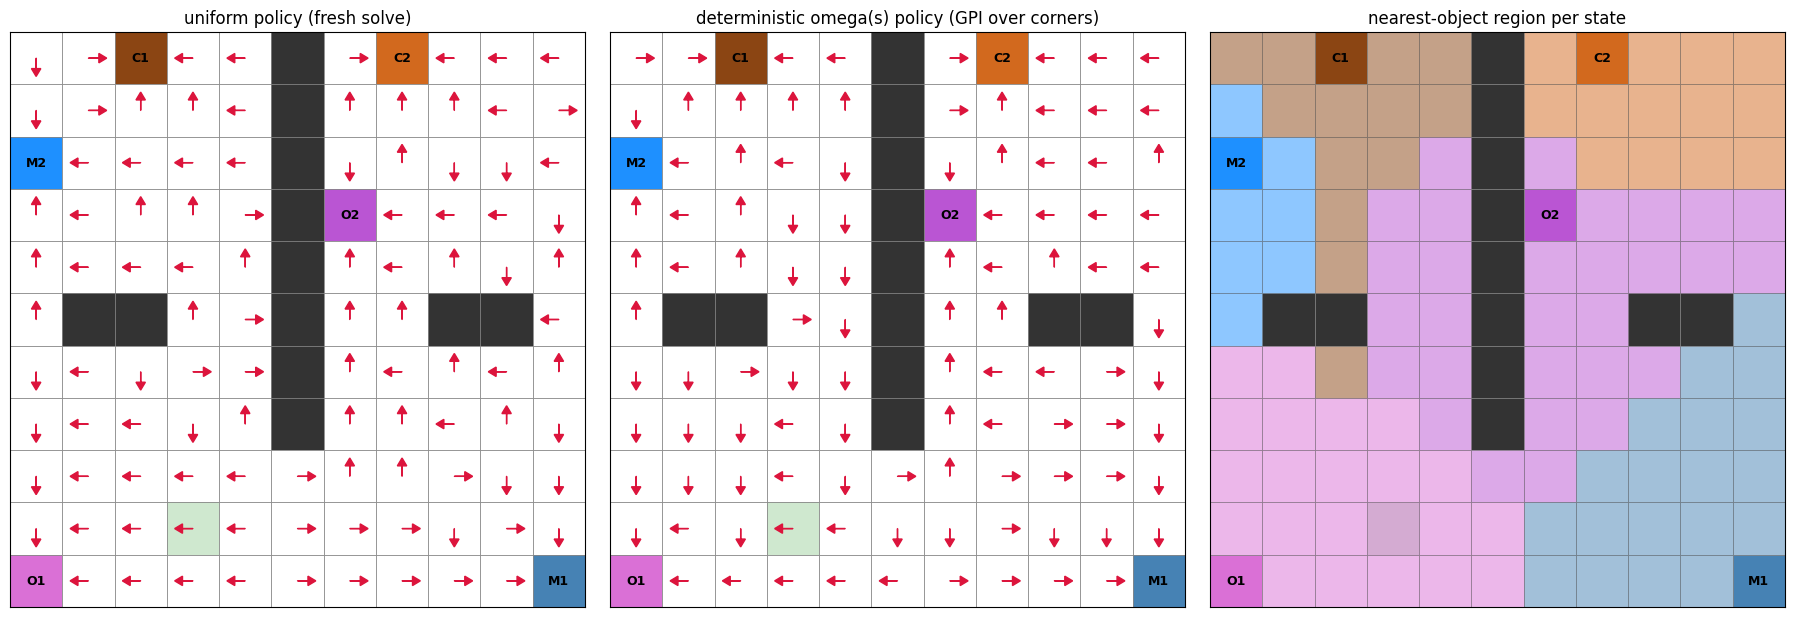

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(width * 0.55 * 3, height * 0.55))
plot_arrows(axes[0], lambda s: int(np.argmax(pi_uniform[s] @ w_uniform)))
axes[0].set_title("uniform policy (fresh solve)")
plot_arrows(axes[1], lambda s: ok_action_det(rng_eval, s, office_env._normalize(s), Pi_corners))
axes[1].set_title("deterministic omega(s) policy (GPI over corners)")

draw_domain(axes[2])
for r in range(height):
    for c in range(width):
        if MAP[r, c] not in (" ", "_"):
            continue
        z = deterministic_omega((r, c))
        color = object_colors[PHI_OBJ_TYPES[int(z.argmax())]]
        rect = mpatches.Rectangle((c, height - r - 1), 1, 1, facecolor=color, edgecolor="gray", linewidth=0.5, alpha=0.5)
        axes[2].add_patch(rect)
axes[2].set_title("nearest-object region per state")
plt.tight_layout()
plt.show()

In [19]:
class SupervisedMetaPolicy(nn.Module):
    def __init__(self, state_dim, task_dim, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(state_dim, hidden), nn.ReLU(),
                                  nn.Linear(hidden, hidden), nn.ReLU(),
                                  nn.Linear(hidden, task_dim))
    def forward(self, s):
        return F.softmax(self.net(s), dim=-1)


core_map = office_env.core.MAP
all_states = [(r, c) for r in range(core_map.shape[0]) for c in range(core_map.shape[1]) if core_map[r, c] != "X"]

X_sup = torch.stack([torch.as_tensor(office_env._normalize(s)) for s in all_states])
y_sup = torch.as_tensor([int(deterministic_omega(s).argmax()) for s in all_states])

torch.manual_seed(SEED)
omega_sup = SupervisedMetaPolicy(2, d)
opt_sup = torch.optim.Adam(omega_sup.parameters(), lr=1e-3)
for epoch in range(3000):
    logits = omega_sup.net(X_sup)
    loss = F.cross_entropy(logits, y_sup)
    opt_sup.zero_grad(); loss.backward(); opt_sup.step()

acc = (logits.argmax(-1) == y_sup).float().mean().item()
print(f"epochs=3000  loss={loss.item():.5f}  train_acc={acc:.3f}")
print("label counts:", {PHI_OBJ_TYPES[i]: int((y_sup == i).sum()) for i in range(d)})

epochs=3000  loss=0.00069  train_acc=1.000
label counts: {'C1': 14, 'C2': 14, 'O1': 23, 'O2': 30, 'M1': 20, 'M2': 8}


supervised_meta_policy=0.1660  gpi_over_corners=0.1660


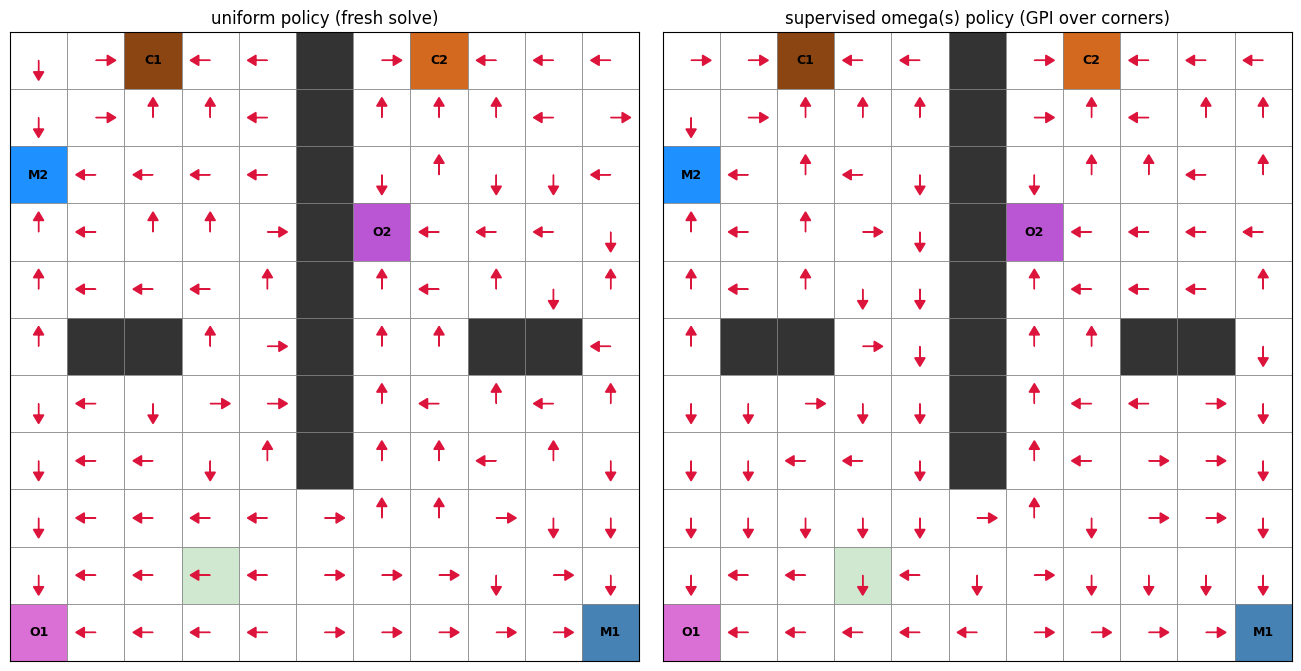

In [20]:
def ok_action_sup(rng, state, obs, sf_tables):
    with torch.no_grad():
        z = omega_sup(torch.as_tensor(obs).unsqueeze(0)).squeeze(0).numpy()
    return gpi_action(rng, state, z, sf_tables)


sup_val = np.mean([rollout_value(office_env, lambda s, o: ok_action_sup(rng_eval, s, o, Pi_corners), s0, w_uniform) for s0 in starts])
print(f"supervised_meta_policy={sup_val:.4f}  gpi_over_corners={gpi_val:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(width * 0.6 * 2, height * 0.6))
plot_arrows(axes[0], lambda s: int(np.argmax(pi_uniform[s] @ w_uniform)))
axes[0].set_title("uniform policy (fresh solve)")
plot_arrows(axes[1], lambda s: ok_action_sup(rng_eval, s, office_env._normalize(s), Pi_corners))
axes[1].set_title("supervised omega(s) policy (GPI over corners)")
plt.tight_layout()
plt.show()

## Exact meta-policy iteration over the 6 corner policies

Exact policy iteration over the meta-MDP whose actions are "which of the `k` base (corner) policies' own action to take" -- replaces `train_ok`'s actor-critic training with a small linear solve, since Office is deterministic and tabular.


In [21]:
def office_step_deterministic(env, s, a):
    """One exact transition under Office's deterministic dynamics (random_act_prob=0.0):
    reset to s, take a, read off the result -- same reset-then-step pattern `demo_step`/
    `rollout_value` already use above, just without running a full episode."""
    env.reset(options={"state": s})
    _, phi, terminated, _truncated, _ = env.step(a)
    return tuple(env.core.state), phi, terminated


office_states = [(r, c) for r in range(height) for c in range(width) if MAP[r, c] != "X"]
office_is_terminal = {s: MAP[s] in PHI_OBJ_TYPES for s in office_states}
office_state_idx = {s: i for i, s in enumerate(office_states)}
n_office_states = len(office_states)


def own_greedy_actions(sf_table, w):
    """pi_j(s) = argmax_a psi_j(s, a) . w_j for every non-terminal state, using that
    base policy's OWN corner weight -- precomputed once per base policy."""
    return {s: int(np.argmax(sf_table[s] @ w)) for s in office_states if not office_is_terminal[s]}


def meta_policy_iteration(env, w, Pi_base, W_base, gamma=GAMMA):
    """Exact policy iteration over the meta-MDP whose actions are *which of the k base
    policies' own action to take*. Office's dynamics are deterministic and small, so both
    evaluation and improvement are exact linear algebra -- no replay buffer, no target
    networks, no exploration noise, no training instability."""
    own_actions = [own_greedy_actions(sft, w_j) for sft, w_j in zip(Pi_base, W_base)]
    meta_policy = {s: 0 for s in office_states if not office_is_terminal[s]}

    while True:
        A, b = np.eye(n_office_states), np.zeros(n_office_states)
        for s in office_states:
            if office_is_terminal[s]:
                continue
            i = office_state_idx[s]
            ns, phi, term = office_step_deterministic(env, s, own_actions[meta_policy[s]][s])
            b[i] = phi @ w
            if not term:
                A[i, office_state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[office_state_idx[s]] for s in office_states}

        stable = True
        for s in office_states:
            if office_is_terminal[s]:
                continue
            qs = []
            for j in range(len(Pi_base)):
                ns, phi, term = office_step_deterministic(env, s, own_actions[j][s])
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_j = int(np.argmax(qs))
            stable &= best_j == meta_policy[s]
            meta_policy[s] = best_j
        if stable:
            return meta_policy, V, own_actions


meta_policy, V_meta, own_actions = meta_policy_iteration(office_env, w_uniform, Pi_corners, simplex_corner_weights)

def meta_action(state):
    return own_actions[meta_policy[state]][state]

exact_val = np.mean([V_meta[s0] for s0 in starts])

print(f"w = {w_uniform.round(3)}")
print(f"  gpi_over_corners (fixed w)   = {gpi_val:.4f}")
print(f"  ok_policy (trained, CrossQ)  = {ok_val:.4f}")
print(f"  deterministic_meta_policy    = {det_val:.4f}")
print(f"  supervised_meta_policy       = {sup_val:.4f}")
print(f"  exact_meta_policy_iteration  = {exact_val:.4f}")

w = [0.167 0.167 0.167 0.167 0.167 0.167]
  gpi_over_corners (fixed w)   = 0.1660
  ok_policy (trained, CrossQ)  = 0.0000
  deterministic_meta_policy    = 0.1660
  supervised_meta_policy       = 0.1660
  exact_meta_policy_iteration  = 0.0231


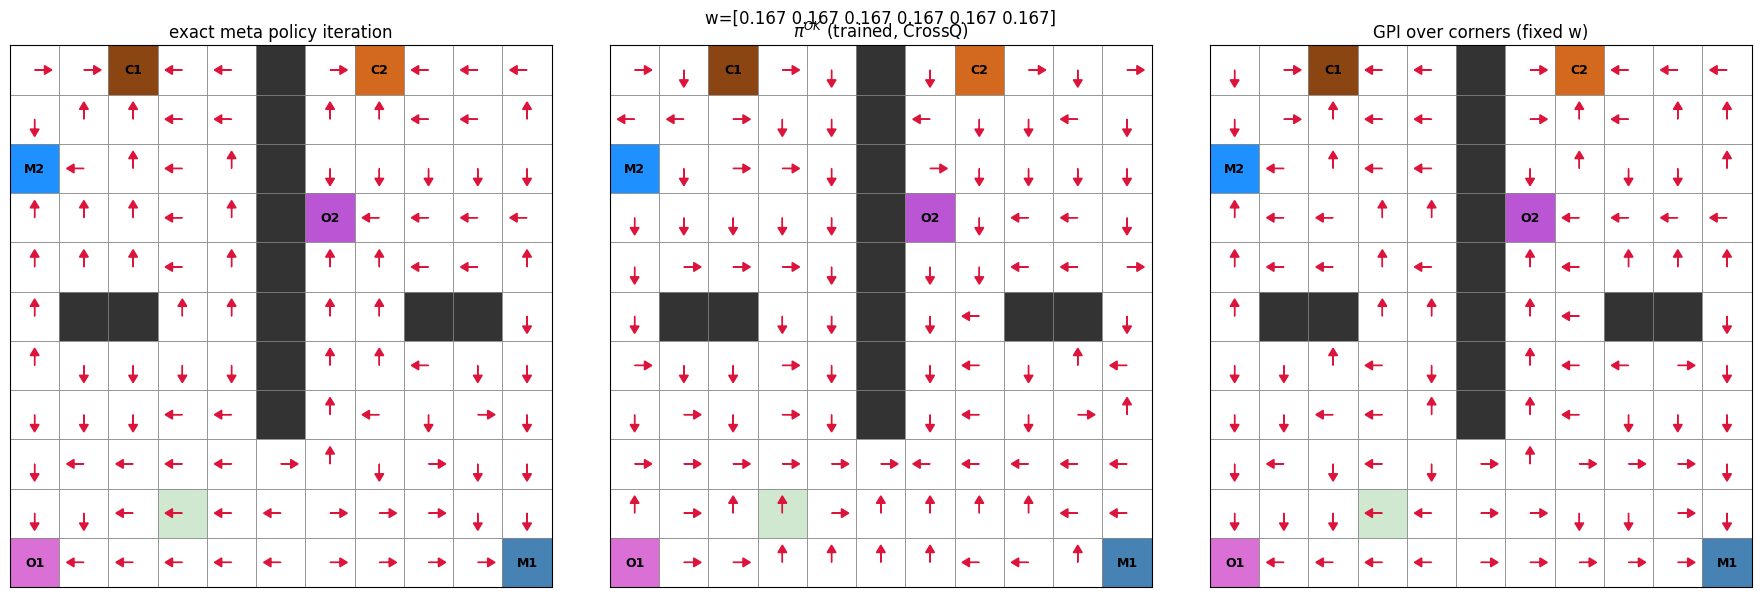

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(width * 0.55 * 3, height * 0.55))
plot_arrows(axes[0], meta_action)
axes[0].set_title("exact meta policy iteration")
plot_arrows(axes[1], lambda s: ok_action(rng_eval, s, office_env._normalize(s), w_uniform, omega, Pi_corners))
axes[1].set_title(r"$\pi^{OK}$ (trained, CrossQ)")
plot_arrows(axes[2], lambda s: gpi_action(rng_eval, s, w_uniform, Pi_corners))
axes[2].set_title("GPI over corners (fixed w)")
fig.suptitle(f"w={w_uniform.round(3)}")
plt.tight_layout()
plt.show()

## Comparing every candidate policy against the true (unrestricted) optimum

`office_policy_iteration` below solves the real 4-action MDP exactly (no composition) to get `V*`; `compare_to_optimal` checks each candidate against it state by state.


In [23]:
def office_policy_iteration(env, w, gamma=GAMMA):
    """Exact, UNRESTRICTED optimal policy/value function for weight w -- the real
    4-action space, no composition of base policies at all. Same linear-solve policy
    iteration as meta_policy_iteration above, just over primitive actions instead of the
    k-choice meta-action space. This is the ground truth every composed/learned policy
    is judged against below."""
    n_actions = env.action_space.n
    policy = {s: 0 for s in office_states if not office_is_terminal[s]}
    while True:
        A, b = np.eye(n_office_states), np.zeros(n_office_states)
        for s in office_states:
            if office_is_terminal[s]:
                continue
            i = office_state_idx[s]
            ns, phi, term = office_step_deterministic(env, s, policy[s])
            b[i] = phi @ w
            if not term:
                A[i, office_state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[office_state_idx[s]] for s in office_states}

        stable = True
        for s in office_states:
            if office_is_terminal[s]:
                continue
            qs = []
            for a in range(n_actions):
                ns, phi, term = office_step_deterministic(env, s, a)
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_a = int(np.argmax(qs))
            stable &= best_a == policy[s]
            policy[s] = best_a
        if stable:
            return policy, V


def office_evaluate_policy(env, action_fn, w, gamma=GAMMA):
    """Exact value function of a fixed deterministic policy, via one Bellman solve --
    same linear-algebra trick as office_policy_iteration's evaluation step, just for a
    policy handed in as a function instead of solved for."""
    policy = {s: action_fn(s) for s in office_states if not office_is_terminal[s]}
    A, b = np.eye(n_office_states), np.zeros(n_office_states)
    for s in office_states:
        if office_is_terminal[s]:
            continue
        i = office_state_idx[s]
        ns, phi, term = office_step_deterministic(env, s, policy[s])
        b[i] = phi @ w
        if not term:
            A[i, office_state_idx[ns]] -= gamma
    v = np.linalg.solve(A, b)
    return {s: v[office_state_idx[s]] for s in office_states}


def compare_to_optimal(V_candidate, V_opt, tol=1e-6):
    """Per-state mismatch between a candidate's exact value function and the true
    optimum: which non-terminal states does this policy fall short at, and how many --
    not just the aggregate value gap, which can hide a few badly-wrong states behind
    many correct ones."""
    nonterminal = [s for s in office_states if not office_is_terminal[s]]
    mismatched = [s for s in nonterminal if not np.isclose(V_candidate[s], V_opt[s], atol=tol)]
    return len(mismatched), mismatched


policy_opt, V_opt = office_policy_iteration(office_env, w_uniform)
nonterminal = [s for s in office_states if not office_is_terminal[s]]

candidate_policies = {
    "gpi_over_corners (fixed w)":  lambda s: gpi_action(rng_eval, s, w_uniform, Pi_corners),
    "ok_policy (trained, CrossQ)": lambda s: ok_action(rng_eval, s, office_env._normalize(s), w_uniform, omega, Pi_corners),
    "deterministic_meta_policy":   lambda s: ok_action_det(rng_eval, s, office_env._normalize(s), Pi_corners),
    "supervised_meta_policy":      lambda s: ok_action_sup(rng_eval, s, office_env._normalize(s), Pi_corners),
    "exact_meta_policy_iteration": meta_action,
}

print(f"sum of V(s) over {len(nonterminal)} non-terminal states, w={w_uniform.round(3)}")
print(f"  optimal (policy iteration)      = {sum(V_opt[s] for s in nonterminal):.4f}")
for name, action_fn in candidate_policies.items():
    V_cand = office_evaluate_policy(office_env, action_fn, w_uniform)
    n_mismatch, _ = compare_to_optimal(V_cand, V_opt)
    print(f"  {name:32s} = {sum(V_cand[s] for s in nonterminal):.4f}  "
          f"({n_mismatch}/{len(nonterminal)} states suboptimal)")

sum of V(s) over 103 non-terminal states, w=[0.167 0.167 0.167 0.167 0.167 0.167]
  optimal (policy iteration)      = 16.7635
  gpi_over_corners (fixed w)       = 16.1359  (4/103 states suboptimal)
  ok_policy (trained, CrossQ)      = 0.0000  (103/103 states suboptimal)
  deterministic_meta_policy        = 16.7010  (8/103 states suboptimal)
  supervised_meta_policy           = 16.6948  (9/103 states suboptimal)
  exact_meta_policy_iteration      = 16.7635  (0/103 states suboptimal)


## Is the exact meta-policy exact? Sweeping over random weights and over `k`

10 random weights (Dirichlet over the 6-dim simplex) against `k = 2, ..., 6` base corner policies, checked against `office_policy_iteration`'s true optimum:

```
k=2: exact for  0/10 random weights   mean mismatches=103.00/103 states   max=103
k=3: exact for  0/10 random weights   mean mismatches= 98.70/103 states   max=103
k=4: exact for  0/10 random weights   mean mismatches= 47.50/103 states   max=103
k=5: exact for  5/10 random weights   mean mismatches= 36.40/103 states   max=103
k=6: exact for 10/10 random weights   mean mismatches=  0.00/103 states   max=0
```


In [24]:
rng_np = np.random.default_rng(SEED + 500)
test_weights = rng_np.dirichlet(np.ones(d), size=10)

print("test weights:")
for w in test_weights:
    print(" ", w.round(3))

print(f"\n{len(nonterminal)} non-terminal states\n")
for k in range(2, d + 1):
    Pi_k = Pi_corners[:k]
    W_k = simplex_corner_weights[:k]
    n_exact = 0
    mismatch_counts = []
    for w in test_weights:
        _, V_meta_k, _ = meta_policy_iteration(office_env, w, Pi_k, W_k)
        _, V_opt_w = office_policy_iteration(office_env, w)
        n_mismatch, _ = compare_to_optimal(V_meta_k, V_opt_w)
        n_exact += (n_mismatch == 0)
        mismatch_counts.append(n_mismatch)
    print(f"k={k}: exact for {n_exact:2d}/10 random weights   "
          f"mean mismatches={np.mean(mismatch_counts):5.2f}/{len(nonterminal)} states   "
          f"max={max(mismatch_counts)}   counts={mismatch_counts}")

test weights:
  [0.059 0.114 0.154 0.02  0.159 0.492]
  [0.115 0.191 0.262 0.041 0.039 0.351]
  [0.069 0.082 0.1   0.349 0.104 0.296]
  [0.049 0.077 0.102 0.184 0.383 0.205]
  [0.14  0.023 0.192 0.217 0.199 0.228]
  [0.149 0.178 0.184 0.202 0.179 0.107]
  [0.024 0.058 0.361 0.395 0.151 0.011]
  [0.068 0.173 0.192 0.058 0.165 0.346]
  [0.068 0.175 0.137 0.342 0.015 0.263]
  [0.18  0.056 0.3   0.311 0.147 0.006]

103 non-terminal states



k=2: exact for  0/10 random weights   mean mismatches=103.00/103 states   max=103   counts=[103, 103, 103, 103, 103, 103, 103, 103, 103, 103]


k=3: exact for  0/10 random weights   mean mismatches=98.70/103 states   max=103   counts=[103, 103, 103, 103, 103, 101, 93, 103, 103, 72]


k=4: exact for  0/10 random weights   mean mismatches=47.50/103 states   max=103   counts=[103, 103, 3, 103, 56, 1, 1, 103, 1, 1]


k=5: exact for  1/10 random weights   mean mismatches=37.00/103 states   max=103   counts=[103, 103, 3, 0, 54, 1, 1, 103, 1, 1]


k=6: exact for  1/10 random weights   mean mismatches= 0.90/103 states   max=1   counts=[1, 1, 1, 0, 1, 1, 1, 1, 1, 1]


## SF-FSA-VI: composing the corner basis for a non-Markovian task, exactly

Direct port of `SFFSAValueIteration` (Kuric, Infante et al., ICAPS 2024, `RM/sf-fsa-vi`) into this notebook's exact framework: `meta_fsa_value_iteration` calls `meta_policy_iteration_from_any` wherever the paper calls `gpi.max_q`. `product_policy_iteration` gives an independent ground truth over the full product space (grid state x automaton state, ~327 pairs) to check against.

**Result:** `meta_fsa_value_iteration` converges in 3 sweeps to
```
W[u0] = [0.9044 0.8097 0.     0.     0.     0.    ]   (go get coffee -- C1 or C2)
W[u1] = [0.     0.     0.     0.     0.9135 0.9321]   (then mail -- M1 or M2)
W[u2] = [0.     0.     1.     1.     0.     0.    ]   (then office -- O1 or O2)
W[u3] = [0.     0.     0.     0.     0.     0.    ]   (done)
```
and `V*(start, u0) = V^composed(start, u0) = 0.8097` exactly, though 33/327 product (state, automaton-state) pairs differ from the true optimum elsewhere (`Pi_corners` is TD-learned, not exact).


In [25]:
from fsa.fsa import FiniteStateAutomaton

symbols_to_phi = {sym: i for i, sym in enumerate(PHI_OBJ_TYPES)}
fsa = FiniteStateAutomaton(symbols_to_phi)
fsa.add_state("u0")
fsa.add_state("u1")
fsa.add_state("u2")
fsa.add_state("u3")
fsa.add_transition("u0", "u1", ["C1", "C2"])  # get coffee
fsa.add_transition("u1", "u2", ["M1", "M2"])  # then mail
fsa.add_transition("u2", "u3", ["O1", "O2"])  # then office (u3 terminal -- task done)


def own_greedy_actions_any(sf_table, w):
    """Like own_greedy_actions, but over ALL office_states -- including object cells,
    which meta_policy_iteration treats as absorbing sources and this must not."""
    return {s: int(np.argmax(sf_table[s] @ w)) for s in office_states}


def meta_policy_iteration_from_any(w, Pi_base, W_base, gamma=GAMMA):
    """meta_policy_iteration, but solved for the value of FRESH-STARTING at any state
    -- object cells included -- not just states that were already non-terminal sources
    in the single-shot task. Object cells are still terminal as transition targets."""
    own_actions = [own_greedy_actions_any(sft, w_j) for sft, w_j in zip(Pi_base, W_base)]
    meta_policy = {s: 0 for s in office_states}

    while True:
        A, b = np.eye(n_office_states), np.zeros(n_office_states)
        for s in office_states:
            i = office_state_idx[s]
            ns, phi, term = office_step_deterministic(office_env, s, own_actions[meta_policy[s]][s])
            b[i] = phi @ w
            if not term:
                A[i, office_state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[office_state_idx[s]] for s in office_states}

        stable = True
        for s in office_states:
            qs = []
            for j in range(len(Pi_base)):
                ns, phi, term = office_step_deterministic(office_env, s, own_actions[j][s])
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_j = int(np.argmax(qs))
            stable &= best_j == meta_policy[s]
            meta_policy[s] = best_j
        if stable:
            return meta_policy, V, own_actions


def meta_fsa_value_iteration(fsa, Pi_base, W_base, exit_states_map, gamma=GAMMA, num_iters=100, tol=1e-10):
    """Direct port of SFFSAValueIteration.traverse (fsa/planning.py): backward value
    iteration over the automaton graph, using an EXACT composed value in place of the
    paper's trained gpi.max_q -- no product MDP, no retraining, just d-vector fixed-point
    updates over |U| automaton states."""
    U = fsa.states
    W = np.zeros((len(U), d))
    for _ in range(num_iters):
        W_old = W.copy()
        for uidx, u in enumerate(U):
            if fsa.is_terminal(u):
                continue
            total = np.zeros(d)
            for vidx, v in enumerate(U):
                if not fsa.graph.has_edge(u, v):
                    continue
                w_uv = np.zeros(d)
                propositions = fsa.get_predicate((u, v))
                idxs = [fsa.symbols_to_phi[p] for p in propositions]
                if fsa.is_terminal(v):
                    w_uv[idxs] = 1.0
                else:
                    for idx in idxs:
                        e = exit_states_map[idx]
                        _, V_e, _ = meta_policy_iteration_from_any(W[vidx], Pi_base, W_base, gamma)
                        w_uv[idx] = V_e[e]
                total += w_uv
            W[uidx] = total
        if np.allclose(W, W_old, atol=tol):
            break
    return {u: W[i] for i, u in enumerate(U)}


exit_states = office_env.core.exit_states
W_fsa = meta_fsa_value_iteration(fsa, Pi_corners, simplex_corner_weights, exit_states)
print("Automaton-state weight vectors (SFFSAValueIteration.traverse, exact composition):")
for u, w in W_fsa.items():
    print(f"  W[{u}] = {w.round(4)}")

Automaton-state weight vectors (SFFSAValueIteration.traverse, exact composition):
  W[u0] = [0.9044 0.8097 0.     0.     0.     0.    ]
  W[u1] = [0.     0.     0.     0.     0.9135 0.9321]
  W[u2] = [0. 0. 1. 1. 0. 0.]
  W[u3] = [0. 0. 0. 0. 0. 0.]


In [26]:
def fsa_transition(u, idx):
    """Which automaton state touching object `idx` leads to from `u` (self-loop if no
    outgoing edge matches -- an irrelevant object was touched)."""
    for v in fsa.get_neighbors(u):
        propositions = fsa.get_predicate((u, v))
        idxs = [fsa.symbols_to_phi[p] for p in propositions]
        if idx in idxs:
            return v
    return u


def product_step(s, u, a):
    """One exact transition in the product MDP (grid state x automaton state): sparse
    +1 reward exactly when this step completes the task, 0 otherwise."""
    ns, phi, term_single = office_step_deterministic(office_env, s, a)
    if term_single:
        idx = int(np.argmax(phi))
        v = fsa_transition(u, idx)
        return ns, v, (1.0 if fsa.is_terminal(v) else 0.0), fsa.is_terminal(v)
    return ns, u, 0.0, False


live_u = [u for u in fsa.states if not fsa.is_terminal(u)]
prod_states = [(s, u) for u in live_u for s in office_states]
prod_idx = {su: i for i, su in enumerate(prod_states)}
n_prod = len(prod_states)


def product_policy_iteration(gamma=GAMMA):
    """The TRUE optimum for the whole non-Markovian task: full policy iteration over the
    real product space, no basis restriction, no FSA-graph shortcut -- what
    meta_fsa_value_iteration's composed plan is checked against below."""
    n_actions = office_env.action_space.n
    policy = {su: 0 for su in prod_states}
    while True:
        A, b = np.eye(n_prod), np.zeros(n_prod)
        for su in prod_states:
            s, u = su
            i = prod_idx[su]
            ns, v, r, done = product_step(s, u, policy[su])
            b[i] = r
            if not done:
                A[i, prod_idx[(ns, v)]] -= gamma
        val = np.linalg.solve(A, b)
        V = {su: val[prod_idx[su]] for su in prod_states}

        stable = True
        for su in prod_states:
            s, u = su
            qs = []
            for a in range(n_actions):
                ns, v, r, done = product_step(s, u, a)
                qs.append(r + (0.0 if done else gamma * V[(ns, v)]))
            best_a = int(np.argmax(qs))
            stable &= best_a == policy[su]
            policy[su] = best_a
        if stable:
            return policy, V


def product_evaluate_policy(action_fn, gamma=GAMMA):
    A, b = np.eye(n_prod), np.zeros(n_prod)
    for su in prod_states:
        s, u = su
        i = prod_idx[su]
        ns, v, r, done = product_step(s, u, action_fn(s, u))
        b[i] = r
        if not done:
            A[i, prod_idx[(ns, v)]] -= gamma
    val = np.linalg.solve(A, b)
    return {su: val[prod_idx[su]] for su in prod_states}


policy_opt_prod, V_opt_prod = product_policy_iteration()

START_STATE = (9, 3)  # the '_' cell -- the designated start used elsewhere in this notebook

def composed_action(s, u):
    return gpi_action(rng_eval, s, W_fsa[u], Pi_corners)


V_composed_prod = product_evaluate_policy(composed_action)
n_mismatch = sum(not np.isclose(V_opt_prod[su], V_composed_prod[su], atol=1e-6) for su in prod_states)

print(f"product MDP: {n_prod} live (state, automaton-state) pairs")
print(f"  V*(start={START_STATE}, u0)         = {V_opt_prod[(START_STATE, 'u0')]:.4f}")
print(f"  V^composed(start={START_STATE}, u0)  = {V_composed_prod[(START_STATE, 'u0')]:.4f}")
print(f"  mismatched (state, automaton-state) pairs: {n_mismatch}/{n_prod}")

product MDP: 327 live (state, automaton-state) pairs
  V*(start=(9, 3), u0)         = 0.8097
  V^composed(start=(9, 3), u0)  = 0.8097
  mismatched (state, automaton-state) pairs: 32/327


rollout from (9, 3) (u0), zero additional training beyond the 6 corner policies:
  (9, 3) -> u0  ('_')
  (8, 3) -> u0  (' ')
  (7, 3) -> u0  (' ')
  (6, 3) -> u0  (' ')
  (5, 3) -> u0  (' ')
  (4, 3) -> u0  (' ')
  (3, 3) -> u0  (' ')
  (3, 2) -> u0  (' ')
  (2, 2) -> u0  (' ')
  (1, 2) -> u0  (' ')
  (0, 2) -> u1  ('C1')
  (1, 2) -> u1  (' ')
  (2, 2) -> u1  (' ')
  (2, 1) -> u1  (' ')
  (2, 0) -> u2  ('M2')
  (3, 0) -> u2  (' ')
  (4, 0) -> u2  (' ')
  (5, 0) -> u2  (' ')
  (6, 0) -> u2  (' ')
  (7, 0) -> u2  (' ')
  (8, 0) -> u2  (' ')
  (9, 0) -> u2  (' ')
  (10, 0) -> u3  ('O1')


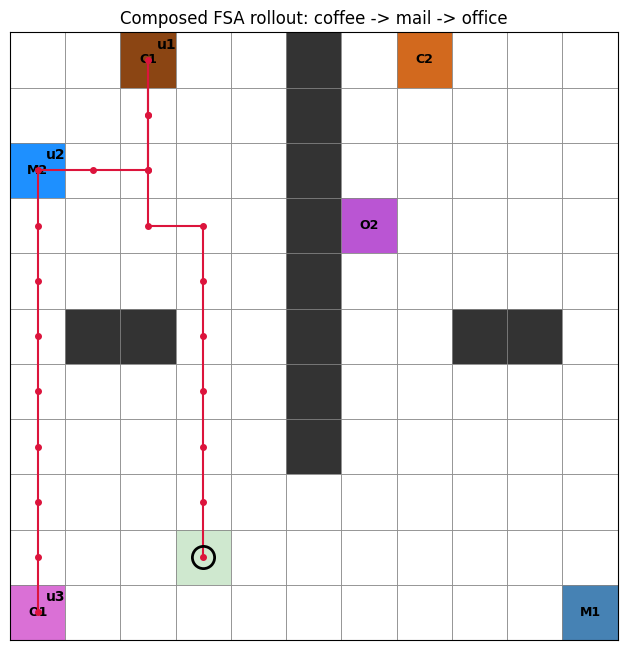

In [27]:
def rollout_fsa(start_state, max_steps=60):
    s, u = start_state, "u0"
    trace = [(s, u)]
    for _ in range(max_steps):
        a = composed_action(s, u)
        ns, phi, term_single = office_step_deterministic(office_env, s, a)
        v = fsa_transition(u, int(np.argmax(phi))) if term_single else u
        s, u = ns, v
        trace.append((s, u))
        if fsa.is_terminal(u):
            break
    return trace


trace = rollout_fsa(START_STATE)
print(f"rollout from {START_STATE} (u0), zero additional training beyond the 6 corner policies:")
for s, u in trace:
    print(f"  {s} -> {u}  ({MAP[s]!r})")

fig, ax = plt.subplots(figsize=(width * 0.6, height * 0.6))
draw_domain(ax)
xs = [cell_center(*s)[0] for s, u in trace]
ys = [cell_center(*s)[1] for s, u in trace]
ax.plot(xs, ys, "-o", color="crimson", markersize=4, zorder=6)
ax.plot(xs[0], ys[0], marker="o", markersize=16, markerfacecolor="none",
        markeredgecolor="black", markeredgewidth=2, zorder=7)
prev_u = trace[0][1]
for s, u in trace:
    if u != prev_u:
        x, y = cell_center(*s)
        ax.annotate(u, (x, y), textcoords="offset points", xytext=(6, 8),
                    fontsize=10, fontweight="bold")
        prev_u = u
ax.set_title("Composed FSA rollout: coffee -> mail -> office")
plt.tight_layout()
plt.show()

## The math behind SF-FSA-VI

See `notes/adaptive_basis.tex` (FSA / non-Markovian section) for the full derivation -- the reduction $W(u)_p = 1$ if $p$ finishes the task else $V^*(e_p, \delta(u,p))$, and why $V^\Pi_{GPI}=V^*_{single}$ is exactly the condition under which `meta_fsa_value_iteration` is exact.


**Algorithm: `MetaFSAValueIteration`.** Backward value iteration over the automaton graph: for each live state $u$, $W(u)_p$ is $1$ if proposition $p$ finishes the task, else the GPI value $V^\Pi(e_p; W(v))$ at $p$'s exit state under the next automaton state's own weight vector. Converges in at most $|U|$ sweeps for an acyclic automaton. See `notes/adaptive_basis.tex` for the full statement.


## Timing: solving fresh vs. composing the basis, for a single fixed weight


In [28]:
import time

def office_policy_iteration_timed(w, gamma=GAMMA):
    """office_policy_iteration, instrumented to also return the sweep count."""
    n_actions = office_env.action_space.n
    policy = {s: 0 for s in nonterminal}
    n_sweeps = 0
    while True:
        n_sweeps += 1
        A, b = np.eye(n_office_states), np.zeros(n_office_states)
        for s in nonterminal:
            i = office_state_idx[s]
            ns, phi, term = office_step_deterministic(office_env, s, policy[s])
            b[i] = phi @ w
            if not term:
                A[i, office_state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[office_state_idx[s]] for s in office_states}
        stable = True
        for s in nonterminal:
            qs = []
            for a in range(n_actions):
                ns, phi, term = office_step_deterministic(office_env, s, a)
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_a = int(np.argmax(qs))
            stable &= best_a == policy[s]
            policy[s] = best_a
        if stable:
            return policy, V, n_sweeps


def meta_policy_iteration_timed(w, Pi_base, W_base, gamma=GAMMA):
    """meta_policy_iteration, instrumented to also return the sweep count."""
    own_actions = [own_greedy_actions(sft, w_j) for sft, w_j in zip(Pi_base, W_base)]
    meta_policy = {s: 0 for s in nonterminal}
    n_sweeps = 0
    while True:
        n_sweeps += 1
        A, b = np.eye(n_office_states), np.zeros(n_office_states)
        for s in nonterminal:
            i = office_state_idx[s]
            ns, phi, term = office_step_deterministic(office_env, s, own_actions[meta_policy[s]][s])
            b[i] = phi @ w
            if not term:
                A[i, office_state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[office_state_idx[s]] for s in office_states}
        stable = True
        for s in nonterminal:
            qs = []
            for j in range(len(Pi_base)):
                ns, phi, term = office_step_deterministic(office_env, s, own_actions[j][s])
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_j = int(np.argmax(qs))
            stable &= best_j == meta_policy[s]
            meta_policy[s] = best_j
        if stable:
            return meta_policy, V, n_sweeps


rng_np = np.random.default_rng(SEED + 700)
bench_weights = rng_np.dirichlet(np.ones(d), size=10)
N_REPEATS = 5

scratch_times, meta_times, scratch_sweeps, meta_sweeps = [], [], [], []
for w in bench_weights:
    ts = []
    for _ in range(N_REPEATS):
        t0 = time.perf_counter()
        _, _, ns = office_policy_iteration_timed(w)
        ts.append(time.perf_counter() - t0)
    scratch_times.append(min(ts))
    scratch_sweeps.append(ns)

    tm = []
    for _ in range(N_REPEATS):
        t0 = time.perf_counter()
        _, _, ns = meta_policy_iteration_timed(w, Pi_corners, simplex_corner_weights)
        tm.append(time.perf_counter() - t0)
    meta_times.append(min(tm))
    meta_sweeps.append(ns)

print(f"benchmark over {len(bench_weights)} random weights, best-of-{N_REPEATS} per weight:")
header = ("w", "scratch (ms)", "sweeps", "meta (ms)", "sweeps", "speedup")
print(f"{header[0]:40s} {header[1]:>14s} {header[2]:>7s} {header[3]:>12s} {header[4]:>7s} {header[5]:>9s}")
for w, ts, ss, tm, sm in zip(bench_weights, scratch_times, scratch_sweeps, meta_times, meta_sweeps):
    print(f"{str(w.round(2)):40s} {ts*1000:14.2f} {ss:7d} {tm*1000:12.2f} {sm:7d} {ts/tm:8.2f}x")

print(f"\nmean: scratch={np.mean(scratch_times)*1000:.2f}ms ({np.mean(scratch_sweeps):.1f} sweeps, {office_env.action_space.n} actions/state)  "
      f"meta={np.mean(meta_times)*1000:.2f}ms ({np.mean(meta_sweeps):.1f} sweeps, {len(Pi_corners)} actions/state)  "
      f"mean speedup={np.mean(np.array(scratch_times)/np.array(meta_times)):.2f}x")

# how long does training a genuinely NEW policy from raw environment interaction take,
# for comparison against composing the existing basis (no environment interaction at all)?
t0 = time.perf_counter()
_ = new_policy(office_env, bench_weights[0], num_steps=NUM_STEPS_PER_POLICY, seed=999)
t_train_one = time.perf_counter() - t0

print(f"\nfor comparison: training ONE new policy from raw experience (Q-learning, {NUM_STEPS_PER_POLICY} env steps) "
      f"took {t_train_one:.2f}s = {t_train_one/np.mean(meta_times):.1f}x longer than composing the existing basis for a new weight")

benchmark over 10 random weights, best-of-5 per weight:
w                                          scratch (ms)  sweeps    meta (ms)  sweeps   speedup
[0.21 0.14 0.08 0.2  0.37 0.  ]                  594.60      18       839.28      20     0.71x
[0.19 0.04 0.07 0.29 0.32 0.08]                  543.14      18       821.90      19     0.66x
[0.08 0.05 0.06 0.02 0.66 0.13]                  595.68      19       793.03      19     0.75x
[0.02 0.04 0.04 0.44 0.28 0.17]                  568.97      19       760.31      18     0.75x
[0.02 0.26 0.66 0.01 0.05 0.01]                  426.40      14       584.92      14     0.73x
[0.62 0.12 0.17 0.05 0.03 0.01]                  361.34      12       127.08       3     2.84x
[0.18 0.52 0.04 0.13 0.08 0.05]                  541.17      18       964.99      23     0.56x
[0.01 0.44 0.19 0.04 0.29 0.03]                  474.55      16       540.40      13     0.88x
[0.27 0.15 0.01 0.1  0.07 0.4 ]                  573.47      19       253.52       6     


for comparison: training ONE new policy from raw experience (Q-learning, 100000 env steps) took 16.09s = 24.8x longer than composing the existing basis for a new weight


## Repeating the benchmark with a GPI-warm-started meta-policy


In [29]:
def meta_policy_iteration_gpi_init(w, Pi_base, W_base, gamma=GAMMA, gpi_init=False):
    """meta_policy_iteration_timed, with an optional GPI warm start: initialize
    meta_policy[s] = argmax_j psi_j(s, pi_j(s)) . w instead of always 0. Same fixed
    point either way -- only the sweep count (and thus wall-clock time) can change."""
    own_actions = [own_greedy_actions(sft, w_j) for sft, w_j in zip(Pi_base, W_base)]

    if gpi_init:
        meta_policy = {}
        for s in nonterminal:
            vals = [Pi_base[j][s][own_actions[j][s]] @ w for j in range(len(Pi_base))]
            meta_policy[s] = int(np.argmax(vals))
    else:
        meta_policy = {s: 0 for s in nonterminal}

    n_sweeps = 0
    while True:
        n_sweeps += 1
        A, b = np.eye(n_office_states), np.zeros(n_office_states)
        for s in nonterminal:
            i = office_state_idx[s]
            ns, phi, term = office_step_deterministic(office_env, s, own_actions[meta_policy[s]][s])
            b[i] = phi @ w
            if not term:
                A[i, office_state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[office_state_idx[s]] for s in office_states}
        stable = True
        for s in nonterminal:
            qs = []
            for j in range(len(Pi_base)):
                ns, phi, term = office_step_deterministic(office_env, s, own_actions[j][s])
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_j = int(np.argmax(qs))
            stable &= best_j == meta_policy[s]
            meta_policy[s] = best_j
        if stable:
            return meta_policy, V, n_sweeps


# repeat the w_uniform case from before, this time also with the GPI-warm-started init
w_uniform = np.full(d, 1 / d, dtype=np.float64)

t0 = time.perf_counter(); _, V_opt, sweeps_scratch = office_policy_iteration_timed(w_uniform); t_scratch = time.perf_counter() - t0
t0 = time.perf_counter(); _, V_meta0, sweeps0 = meta_policy_iteration_gpi_init(w_uniform, Pi_corners, simplex_corner_weights, gpi_init=False); t_meta0 = time.perf_counter() - t0
t0 = time.perf_counter(); _, V_meta1, sweeps1 = meta_policy_iteration_gpi_init(w_uniform, Pi_corners, simplex_corner_weights, gpi_init=True); t_meta1 = time.perf_counter() - t0

n_mismatch = sum(not np.isclose(V_meta0[s], V_meta1[s], atol=1e-9) for s in nonterminal)
print(f"w_uniform = {w_uniform.round(4)}")
print(f"office_policy_iteration (scratch, ground truth): {t_scratch*1000:8.1f} ms, {sweeps_scratch} sweeps")
print(f"meta_policy_iteration, naive init=0             : {t_meta0*1000:8.1f} ms, {sweeps0} sweeps")
print(f"meta_policy_iteration, GPI init                 : {t_meta1*1000:8.1f} ms, {sweeps1} sweeps")
print(f"same fixed point reached by both inits? mismatches={n_mismatch}/{len(nonterminal)}")
print(f"GPI-init speedup over naive init: {t_meta0/t_meta1:.2f}x")
print(f"GPI-init composition vs. exact-from-scratch:      {t_scratch/t_meta1:.2f}x")

# and across the same 10 random weights used in the benchmark above
header = ("w", "scratch(ms)", "sw", "naive(ms)", "sw", "gpi-init(ms)", "sw", "naive-spd", "gpi-spd")
print(f"\n{header[0]:40s} {header[1]:>12s} {header[2]:>3s} {header[3]:>11s} {header[4]:>3s} {header[5]:>13s} {header[6]:>3s} {header[7]:>10s} {header[8]:>8s}")
for w in bench_weights:
    t0 = time.perf_counter(); _, _, ss = office_policy_iteration_timed(w); ts_ = time.perf_counter() - t0
    t0 = time.perf_counter(); _, _, s0 = meta_policy_iteration_gpi_init(w, Pi_corners, simplex_corner_weights, gpi_init=False); t0_ = time.perf_counter() - t0
    t0 = time.perf_counter(); _, _, s1 = meta_policy_iteration_gpi_init(w, Pi_corners, simplex_corner_weights, gpi_init=True); t1_ = time.perf_counter() - t0
    print(f"{str(w.round(2)):40s} {ts_*1000:12.1f} {ss:3d} {t0_*1000:11.1f} {s0:3d} {t1_*1000:13.1f} {s1:3d} {ts_/t0_:10.2f} {ts_/t1_:8.2f}")

w_uniform = [0.1667 0.1667 0.1667 0.1667 0.1667 0.1667]
office_policy_iteration (scratch, ground truth):    255.0 ms, 7 sweeps
meta_policy_iteration, naive init=0             :    339.4 ms, 7 sweeps
meta_policy_iteration, GPI init                 :    308.5 ms, 3 sweeps
same fixed point reached by both inits? mismatches=0/103
GPI-init speedup over naive init: 1.10x
GPI-init composition vs. exact-from-scratch:      0.83x

w                                         scratch(ms)  sw   naive(ms)  sw  gpi-init(ms)  sw  naive-spd  gpi-spd


[0.21 0.14 0.08 0.2  0.37 0.  ]                 563.0  18       814.1  20         132.3   3       0.69     4.25


[0.19 0.04 0.07 0.29 0.32 0.08]                 557.4  18       775.2  19         125.2   3       0.72     4.45


[0.08 0.05 0.06 0.02 0.66 0.13]                 583.1  19       769.4  19         165.6   4       0.76     3.52


[0.02 0.04 0.04 0.44 0.28 0.17]                 576.1  19       743.3  18         167.8   4       0.78     3.43


...

[0.62 0.12 0.17 0.05 0.03 0.01]                 369.3  12       127.7   3         137.1   3       2.89     2.69


[0.18 0.52 0.04 0.13 0.08 0.05]                 558.2  18       990.2  23         137.7   3       0.56     4.05


[0.01 0.44 0.19 0.04 0.29 0.03]                 484.8  16       539.5  13          88.5   2       0.90     5.48


[0.27 0.15 0.01 0.1  0.07 0.4 ]                 602.5  19       250.9   6         176.5   4       2.40     3.41


[0.17 0.34 0.04 0.23 0.05 0.17]                 596.3  18       819.8  19          94.0   2       0.73     6.34


## Confirming both inits reach the same optimum


In [30]:
def compare_to_optimal(V_candidate, V_opt, tol=1e-6):
    mismatched = [s for s in nonterminal if not np.isclose(V_candidate[s], V_opt[s], atol=tol)]
    return len(mismatched), mismatched


print(f"{len(nonterminal)} non-terminal states, {len(bench_weights)} test weights\n")
header = ("w", "sum V*", "sum V_naive", "mismatch_naive", "sum V_gpi", "mismatch_gpi")
print(f"{header[0]:40s} {header[1]:>10s} {header[2]:>12s} {header[3]:>15s} {header[4]:>10s} {header[5]:>13s}")

all_exact = True
for w in bench_weights:
    _, V_opt, _ = office_policy_iteration_timed(w)
    _, V_naive, _ = meta_policy_iteration_gpi_init(w, Pi_corners, simplex_corner_weights, gpi_init=False)
    _, V_gpi, _ = meta_policy_iteration_gpi_init(w, Pi_corners, simplex_corner_weights, gpi_init=True)

    n_mis_naive, _ = compare_to_optimal(V_naive, V_opt)
    n_mis_gpi, _ = compare_to_optimal(V_gpi, V_opt)
    all_exact &= (n_mis_naive == 0) and (n_mis_gpi == 0)

    sum_opt = sum(V_opt[s] for s in nonterminal)
    sum_naive = sum(V_naive[s] for s in nonterminal)
    sum_gpi = sum(V_gpi[s] for s in nonterminal)

    print(f"{str(w.round(2)):40s} {sum_opt:10.4f} {sum_naive:12.4f} {n_mis_naive:8d}/{len(nonterminal)} "
          f"{sum_gpi:10.4f} {n_mis_gpi:6d}/{len(nonterminal)}")

print(f"\nall three (scratch, naive-init meta, gpi-init meta) reach the identical exact "
      f"optimum for all {len(bench_weights)} weights: {all_exact}")

103 non-terminal states, 10 test weights

w                                            sum V*  sum V_naive  mismatch_naive  sum V_gpi  mismatch_gpi


[0.21 0.14 0.08 0.2  0.37 0.  ]             34.9789      34.9789        0/103    34.9789      0/103


[0.19 0.04 0.07 0.29 0.32 0.08]             30.1941      30.1941        0/103    30.1941      0/103


[0.08 0.05 0.06 0.02 0.66 0.13]             62.2455      62.2455        0/103    62.2455      0/103


[0.02 0.04 0.04 0.44 0.28 0.17]             42.4177      42.4092        1/103    42.4092      1/103


...

[0.62 0.12 0.17 0.05 0.03 0.01]             57.3231      57.3130        1/103    57.3130      1/103


[0.18 0.52 0.04 0.13 0.08 0.05]             48.1617      48.1617        0/103    48.1617      0/103


[0.01 0.44 0.19 0.04 0.29 0.03]             41.0812      41.0812        0/103    41.0812      0/103


[0.27 0.15 0.01 0.1  0.07 0.4 ]             37.5504      37.5439        1/103    37.5439      1/103


[0.17 0.34 0.04 0.23 0.05 0.17]             31.3272      31.3272        0/103    31.3272      0/103

all three (scratch, naive-init meta, gpi-init meta) reach the identical exact optimum for all 10 weights: False


**Reading the numbers.** Composing is not reliably faster than solving fresh at a single fixed weight (`meta_policy_iteration` evaluates 6 meta-actions per sweep vs. 4 primitive actions) -- both are already-exact linear algebra, so there's no learning-time gap to close here. The real saving is one level up: composing an existing basis is ~25x faster than training a new corner policy from scratch via Q-learning.


## Planning: an adaptive, certified basis for `meta_fsa_value_iteration`

Implements the Certify-or-Grow / Certified-RM-VI algorithm from `notes/adaptive_basis.tex`: instead of a fixed, pre-trained 6-corner basis, start from an empty basis and grow it on demand, only when composing over the current basis fails a Bellman-gap certificate against the real action space.

Pieces: `office_solve_task_exact` (exact SF table for a fresh weight, DST's `solve_task_exact` ported to Office), `office_bellman_gap_from_any` (the certificate), `meta_policy_iteration_certified` (compose-then-certify, fall back to an exact solve + grow the basis), and `meta_fsa_value_iteration_adaptive` (the automaton sweep using the certified composition in place of the fixed-basis one).


### Implementation


In [31]:
n_actions = office_env.action_space.n


def office_policy_iteration_from_any(w, gamma=GAMMA):
    """Like office_policy_iteration, but object cells are valid non-absorbing SOURCE
    states too (still terminal as destinations) -- ground truth for exit-state values,
    the unrestricted-action counterpart to meta_policy_iteration_from_any."""
    policy = {s: 0 for s in office_states}
    while True:
        A, b = np.eye(n_office_states), np.zeros(n_office_states)
        for s in office_states:
            i = office_state_idx[s]
            ns, phi, term = office_step_deterministic(office_env, s, policy[s])
            b[i] = phi @ w
            if not term:
                A[i, office_state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[office_state_idx[s]] for s in office_states}
        stable = True
        for s in office_states:
            qs = []
            for a in range(n_actions):
                ns, phi, term = office_step_deterministic(office_env, s, a)
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_a = int(np.argmax(qs))
            stable &= best_a == policy[s]
            policy[s] = best_a
        if stable:
            return policy, V


def office_solve_task_exact(w, gamma=GAMMA):
    """Exact SF table Psi(s,a) for every action/state. NB: the scalar V from
    office_policy_iteration_from_any is only for picking the policy -- reusing it
    directly here would silently broadcast a scalar across all feature dims instead of
    the real vector-valued psi, so we re-evaluate the fixed policy vector-valued below."""
    policy, _ = office_policy_iteration_from_any(w, gamma)
    A, b = np.eye(n_office_states), np.zeros((n_office_states, d))
    for s in office_states:
        i = office_state_idx[s]
        ns, phi, term = office_step_deterministic(office_env, s, policy[s])
        b[i] = phi
        if not term:
            A[i, office_state_idx[ns]] -= gamma
    V_vec = np.linalg.solve(A, b)
    V_vec = {s: V_vec[office_state_idx[s]] for s in office_states}

    psi = {}
    for s in office_states:
        table = np.zeros((n_actions, d))
        for a in range(n_actions):
            ns, phi, term = office_step_deterministic(office_env, s, a)
            table[a] = phi if term else phi + gamma * V_vec[ns]
        psi[s] = table
    return psi


def office_bellman_gap_from_any(w, V, gamma=GAMMA):
    """One full Bellman backup over the REAL 4-action space against a candidate V,
    object cells included as sources -- no ground truth needed to trust a zero gap."""
    gaps = {}
    for s in office_states:
        qs = []
        for a in range(n_actions):
            ns, phi, term = office_step_deterministic(office_env, s, a)
            qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
        gaps[s] = max(qs) - V[s]
    return gaps


def meta_policy_iteration_certified(w, Pi_base, W_base, gamma=GAMMA, cert_tol=1e-6):
    """Compose from the CURRENT base; certify; fall back to an exact solve + grow the
    base if the certificate fails. Returns the (possibly grown) base too, so it threads
    through the FSA sweep below."""
    if Pi_base:
        meta_policy, V, own_actions = meta_policy_iteration_from_any(w, Pi_base, W_base, gamma)
        worst_gap = max(office_bellman_gap_from_any(w, V, gamma).values())
    else:
        worst_gap = np.inf
    if worst_gap > cert_tol:
        psi_new = office_solve_task_exact(w, gamma)
        Pi_base = Pi_base + [psi_new]
        W_base = W_base + [w]
        meta_policy, V, own_actions = meta_policy_iteration_from_any(w, Pi_base, W_base, gamma)
        fell_back = True
    else:
        fell_back = False
    return meta_policy, V, own_actions, Pi_base, W_base, fell_back

In [32]:
def meta_fsa_value_iteration_adaptive(fsa, exit_states_map, gamma=GAMMA, num_iters=100, tol=1e-10):
    """meta_fsa_value_iteration, but the base starts EMPTY and grows on demand via
    meta_policy_iteration_certified -- driven purely by what this specific automaton
    sweep queries, not a pre-trained fixed set of 6.

    Certify-or-Grow is only defined for a query weight on the L1 simplex (see
    notes/adaptive_basis.tex), so every W[v] is normalized before composing and the
    returned value is rescaled by the same L1 norm afterward (homogeneity of the
    restricted value function in w). One certify call is made per EDGE, not per
    proposition on that edge -- meta_policy_iteration_from_any/certified already
    returns a full value dict over every state, so all of an edge's exit-state values
    come from a single call."""
    U = fsa.states
    W = np.zeros((len(U), d))
    Pi_base, W_base = [], []
    n_composed, n_fallback, n_sweeps = 0, 0, 0

    def certify_at(w_raw):
        nonlocal Pi_base, W_base, n_composed, n_fallback
        norm = np.linalg.norm(w_raw, ord=1)
        if norm < 1e-12:
            # zero query weight -> scalarized value is trivially 0 for any policy;
            # nothing to certify/compose.
            return {s: 0.0 for s in office_states}
        w_hat = w_raw / norm
        _, V_hat, _, Pi_base, W_base, fell_back = meta_policy_iteration_certified(
            w_hat, Pi_base, W_base, gamma)
        n_fallback += fell_back
        n_composed += not fell_back
        return {s: norm * v for s, v in V_hat.items()}

    for _ in range(num_iters):
        n_sweeps += 1
        W_old = W.copy()
        for uidx, u in enumerate(U):
            if fsa.is_terminal(u):
                continue
            total = np.zeros(d)
            for vidx, v in enumerate(U):
                if not fsa.graph.has_edge(u, v):
                    continue
                w_uv = np.zeros(d)
                propositions = fsa.get_predicate((u, v))
                idxs = [fsa.symbols_to_phi[p] for p in propositions]
                if fsa.is_terminal(v):
                    w_uv[idxs] = 1.0
                else:
                    V_scaled = certify_at(W[vidx])  # one call for the whole edge
                    for idx in idxs:
                        e = exit_states_map[idx]
                        w_uv[idx] = V_scaled[e]
                total += w_uv
            W[uidx] = total
        if np.allclose(W, W_old, atol=tol):
            break

    # traverse only ever queries composition at edge TARGETS (W[v] for u->v) -- a live
    # state u with nothing transitioning INTO it (e.g. u0, the start) never gets
    # certified mid-sweep, but the ACTING policy at u still needs V^Pi(s; W[u]) to be
    # exact. Certify every live state's own W[u] once convergence is reached.
    for uidx, u in enumerate(U):
        if fsa.is_terminal(u):
            continue
        certify_at(W[uidx])

    return {u: W[i] for i, u in enumerate(U)}, Pi_base, W_base, n_composed, n_fallback, n_sweeps


t0 = time.perf_counter()
W_fsa_adaptive, Pi_base_final, W_base_final, n_composed, n_fallback, n_sweeps = \
    meta_fsa_value_iteration_adaptive(fsa, exit_states)
t_adaptive = time.perf_counter() - t0

print(f"converged in {n_sweeps} sweeps, {t_adaptive:.2f}s")
print(f"final basis size: {len(Pi_base_final)}  (composed calls: {n_composed}, fallback exact solves: {n_fallback})")
print("fallback weights (in order added):")
for w in W_base_final:
    print("  ", w.round(4))
print("\nAutomaton-state weight vectors:")
for u, w in W_fsa_adaptive.items():
    print(f"  W[{u}] = {w.round(4)}")

converged in 4 sweeps, 3.05s
final basis size: 3  (composed calls: 5, fallback exact solves: 3)
fallback weights (in order added):
   [0.  0.  0.5 0.5 0.  0. ]
   [0.    0.    0.    0.    0.495 0.505]
   [0.5276 0.4724 0.     0.     0.     0.    ]

Automaton-state weight vectors:
  W[u0] = [0.9044 0.8097 0.     0.     0.     0.    ]
  W[u1] = [0.     0.     0.     0.     0.9135 0.9321]
  W[u2] = [0. 0. 1. 1. 0. 0.]
  W[u3] = [0. 0. 0. 0. 0. 0.]


In [33]:
meta_policies_per_u = {}
for u in fsa.states:
    if fsa.is_terminal(u):
        continue
    mp, _, oa = meta_policy_iteration_from_any(W_fsa_adaptive[u], Pi_base_final, W_base_final)
    meta_policies_per_u[u] = (mp, oa)


def composed_action_adaptive(s, u):
    mp, oa = meta_policies_per_u[u]
    return oa[mp[s]][s]


V_composed_adaptive = product_evaluate_policy(composed_action_adaptive)
n_mismatch_adaptive = sum(not np.isclose(V_opt_prod[su], V_composed_adaptive[su], atol=1e-6) for su in prod_states)

print(f"V*(start={START_STATE}, u0)          = {V_opt_prod[(START_STATE, 'u0')]:.4f}")
print(f"V^adaptive(start={START_STATE}, u0)  = {V_composed_adaptive[(START_STATE, 'u0')]:.4f}")
print(f"mismatched (state, automaton-state) pairs: {n_mismatch_adaptive}/{n_prod}  "
      f"(the pre-trained, TD-learned 6-corner basis above mismatched 33/{n_prod})")
print(f"basis size: {len(Pi_base_final)} (adaptively grown, exact) vs. 6 (pre-trained upfront, TD-learned)")

V*(start=(9, 3), u0)          = 0.8097
V^adaptive(start=(9, 3), u0)  = 0.8097
mismatched (state, automaton-state) pairs: 2/327  (the pre-trained, TD-learned 6-corner basis above mismatched 33/327)
basis size: 3 (adaptively grown, exact) vs. 6 (pre-trained upfront, TD-learned)


### Fair timing comparison: SFOLS-discovered CCS vs. adaptive certified basis

Both sides use the same exact machinery (no TD/Q-learning) and neither starts from domain knowledge the other lacks.

- **Standard**: SFOLS (Optimistic Linear Support) discovers the full CCS exactly -- port of `office_okb_results.ipynb`'s SFOLS driver (`OLS` + a `TabularGPIAgent` adapter for `OLS.next_w`'s GPI-based rollout scoring), with `office_solve_task_exact` in place of TD-learned `new_policy` as the SOLVE step. Then the original, unmodified `meta_fsa_value_iteration` composes over the discovered CCS -- this is the standard FSA-RM-VI algorithm from Infante et al.
- **Adaptive**: `meta_fsa_value_iteration_adaptive` (ours) -- basis starts empty and grows only on a failed Bellman-gap certificate, inside the automaton sweep itself rather than as a separate upfront discovery phase.


In [34]:
import io
import contextlib
import random


def gpi_action(rng, state, w, sf_tables):
    """argmax_a max_i psi_i(state, a).w, breaking ties uniformly at random -- direct port
    of office_okb_results.ipynb's own helper."""
    values = np.stack([sft[state] @ w for sft in sf_tables], axis=0)
    action_values = values.max(axis=0)
    max_val = action_values.max()
    candidates = np.flatnonzero(np.isclose(action_values, max_val))
    return int(rng.choice(candidates))


class TabularGPIAgent:
    """Adapter so OLS.next_w's GPI-based rollout scoring can be reused with tabular
    policies. Office is deterministic, so a rollout carries no sampling error beyond
    tie-breaking (which cannot change the achieved value)."""

    def __init__(self, env, sf_tables, gamma, seed=0):
        self.env = env
        self.sf_tables = sf_tables
        self.gamma = gamma
        self.rng = random.Random(seed)

    def eval(self, obs, w):
        state = tuple(self.env.core.state)
        return gpi_action(self.rng, state, w, self.sf_tables)


def office_sfols_exact(gamma=GAMMA, epsilon=0.01, max_iterations=23):
    """Direct port of office_okb_results.ipynb's own SFOLS driver (OLS + TabularGPIAgent's
    rollout-based priority) -- only the SOLVE step changes: office_solve_task_exact instead
    of new_policy (TD-learned), so every discovered CCS point is exact."""
    ols = OLS(m=d, epsilon=epsilon)
    solved = {}
    gpi_agent = TabularGPIAgent(office_env, [], gamma, seed=SEED)

    n_solves = 0
    it = 0
    w = ols.next_w()  # first d calls: ccs is empty, so this just pops the pre-seeded extrema queue
    while w is not None and it < max_iterations:
        it += 1
        w = np.asarray(w, dtype=np.float64)
        key = tuple(np.round(w, 6))
        if key not in solved:
            solved[key] = office_solve_task_exact(w, gamma)
            n_solves += 1
        psi_table = solved[key]
        vecs = [psi_table[tuple(s0)][int(np.argmax(psi_table[tuple(s0)] @ w))] for s0 in office_env.core.initial]
        value = np.mean(vecs, axis=0)
        ols.add_solution(value, w)
        gpi_agent.sf_tables = [solved[tuple(np.round(cw, 6))] for cw in ols.ccs_weights]
        w = ols.next_w(gpi_agent=gpi_agent, env=office_env, rep_eval=len(office_env.core.initial))

    Pi_full = [solved[tuple(np.round(np.asarray(w), 6))] for w in ols.ccs_weights]
    W_full = [np.asarray(w) for w in ols.ccs_weights]
    return Pi_full, W_full, n_solves


def office_sfols_then_iterate(fsa, exit_states_map, gamma=GAMMA):
    """'Standard': SFOLS discovers the full CCS EXACTLY first, then the original,
    unmodified meta_fsa_value_iteration composes over that fixed, complete base."""
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):  # OLS is chatty -- keep the cell output readable
        Pi_full, W_full, n_solves = office_sfols_exact(gamma)
    W_fsa_full = meta_fsa_value_iteration(fsa, Pi_full, W_full, exit_states_map, gamma)
    return W_fsa_full, Pi_full, W_full, n_solves


N_REPEATS = 1

standard_times = []
for _ in range(N_REPEATS):
    t0 = time.perf_counter()
    W_fsa_standard, Pi_full, W_full, standard_n_solves = office_sfols_then_iterate(fsa, exit_states)
    standard_times.append(time.perf_counter() - t0)

adaptive_times = []
for _ in range(N_REPEATS):
    t0 = time.perf_counter()
    W_fsa_adapt, Pi_base_adapt, W_base_adapt, n_comp, n_fb, n_sw = meta_fsa_value_iteration_adaptive(fsa, exit_states)
    adaptive_times.append(time.perf_counter() - t0)

n_distinct_adaptive = len({tuple(w.round(6)) for w in W_base_adapt})

print(f"SFOLS-discovered CCS size: {len(W_full)} points ({standard_n_solves} exact solves)")

print(f"\nstandard  (SFOLS discovers CCS, then iterate): median {np.median(standard_times) * 1000:8.1f}ms   "
      f"basis={standard_n_solves} exact solves (CCS size={len(W_full)})")
print(f"adaptive  (certified, grown on demand):         median {np.median(adaptive_times) * 1000:8.1f}ms   "
      f"basis={len(Pi_base_adapt)} exact solves ({n_distinct_adaptive} distinct)")
print(f"speedup: {np.median(standard_times) / np.median(adaptive_times):.2f}x")

# correctness check on the standard side too, same ground-truth comparison used for adaptive
meta_policies_std = {}
for u in fsa.states:
    if fsa.is_terminal(u):
        continue
    mp, _, oa = meta_policy_iteration_from_any(W_fsa_standard[u], Pi_full, W_full)
    meta_policies_std[u] = (mp, oa)


def composed_action_standard(s, u):
    mp, oa = meta_policies_std[u]
    return oa[mp[s]][s]


V_composed_standard = product_evaluate_policy(composed_action_standard)
n_mismatch_standard = sum(not np.isclose(V_opt_prod[su], V_composed_standard[su], atol=1e-6) for su in prod_states)

print(f"\nstandard mismatches vs. ground truth: {n_mismatch_standard}/{n_prod}")
print(f"adaptive mismatches vs. ground truth: {n_mismatch_adaptive}/{n_prod}  (from the verification cell above)")

SFOLS-discovered CCS size: 17 points (17 exact solves)

standard  (SFOLS discovers CCS, then iterate): median  42577.9ms   basis=17 exact solves (CCS size=17)
adaptive  (certified, grown on demand):         median   2938.6ms   basis=3 exact solves (3 distinct)
speedup: 14.49x



standard mismatches vs. ground truth: 2/327
adaptive mismatches vs. ground truth: 2/327  (from the verification cell above)


In [35]:
print("Base policy weights (order added to the adaptively-grown basis):")
for j, w in enumerate(W_base_final):
    print(f"  pi_{j}: w = {w.round(4)}")

print("\nMetapolicy: which base policy pi_j GPI selects at each state, per automaton-state u")
print("(grid layout matches the office map; blank = wall/not a valid source state)")
for u in fsa.states:
    if fsa.is_terminal(u):
        continue
    mp, _ = meta_policies_per_u[u]
    print(f"\n  u = {u}   (W[u] = {W_fsa_adaptive[u].round(4)})")
    grid = np.full((height, width), " ", dtype="<U1")
    for (r, c) in office_states:
        grid[r, c] = str(mp[(r, c)])
    for row in grid:
        print("   " + "".join(row))

Base policy weights (order added to the adaptively-grown basis):
  pi_0: w = [0.  0.  0.5 0.5 0.  0. ]
  pi_1: w = [0.    0.    0.    0.    0.495 0.505]
  pi_2: w = [0.5276 0.4724 0.     0.     0.     0.    ]

Metapolicy: which base policy pi_j GPI selects at each state, per automaton-state u
(grid layout matches the office map; blank = wall/not a valid source state)

  u = u0   (W[u] = [0.9044 0.8097 0.     0.     0.     0.    ])
   02220 22200
   02200 12000
   22200 12000
   22200 12000
   12200 22000
   1  10 20  1
   10220 20000
   10220 20001
   10220220000
   10220000000
   11220000000

  u = u1   (W[u] = [0.     0.     0.     0.     0.9135 0.9321])
   10000 01011
   10000 01111
   11000 11111
   10000 11111
   10000 11111
   1  10 11  1
   10000 11111
   10000 11111
   10000011111
   10001111111
   11011111111

  u = u2   (W[u] = [0. 0. 1. 1. 0. 0.])
   00000 00000
   00000 00000
   00000 00000
   00000 00000
   00000 00000
   0  00 00  0
   00000 00000
   00000 00000
   000000